# Potato Leaf Disease Classification — Reproducible CNN, ViT and Ensemble Research

Run **top-to-bottom** on a Kaggle/Colab GPU. The baseline experiments remain intact; optional improvements are in Sections 25–28. **Saved outputs in this copy are HISTORICAL results from the original 20-epoch experiment, NOT results from the revised 30-epoch ViT / 50-epoch CNN configuration. Re-run training and downstream evaluation cells to obtain new metrics.** The test set has previously been inspected: treat new test-set performance as exploratory until validated on an independent locked external set.


In [1]:
!pip install -q kagglehub statsmodels "transformers>=4.40,<5"


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 49.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 34.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 58.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras import layers, models

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score,
    roc_auc_score, confusion_matrix, classification_report
)
from statsmodels.stats.contingency_tables import mcnemar

import kagglehub

tf.random.set_seed(42)
np.random.seed(42)

print("TensorFlow:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Download Dataset

In [3]:
path = kagglehub.dataset_download("warcoder/potato-leaf-disease-dataset")
print(path)
print(os.listdir(path))

Using Colab cache for faster access to the 'potato-leaf-disease-dataset' dataset.
/kaggle/input/potato-leaf-disease-dataset
['Potato Leaf Disease Dataset in Uncontrolled Environment']


In [4]:
dataset_path = os.path.join(path, os.listdir(path)[0])
print(dataset_path)
print(os.listdir(dataset_path))

/kaggle/input/potato-leaf-disease-dataset/Potato Leaf Disease Dataset in Uncontrolled Environment
['Nematode', 'Bacteria', 'Healthy', 'Phytopthora', 'Fungi', 'Pest', 'Virus']


## 3. Global Configuration




In [5]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

# Updated controlled comparison budget: 50 epochs per run (5 frozen + 45 fine-tuning).
# This is an experiment setting, NOT a claim that every model converges in 50 epochs.
# Review validation curves/checkpoints before final model selection.
# Stage 1: train the new classification head with the backbone frozen.
# Stage 2: fine-tune the last UNFREEZE_LAST_N backbone layers.
EPOCHS_PHASE1 = 5      # frozen backbone, train the classification head
EPOCHS_PHASE2 = 45     # fine-tune: unfreeze last N layers of the backbone
TOTAL_EPOCHS = EPOCHS_PHASE1 + EPOCHS_PHASE2
assert TOTAL_EPOCHS > 0
UNFREEZE_LAST_N = 30   # how many backbone layers to unfreeze during fine-tuning

OUTPUT_DIR = "results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

### 3.1 [NEW] Environment & reproducibility record

Writes the software/hardware environment and the random seed to `results/environment.json` so the experiment can be reported and repeated. (GPU kernels can still be slightly non-deterministic, so tiny run-to-run differences are possible even with a fixed seed.)

In [6]:
import sys, platform, sklearn

tf.keras.utils.set_random_seed(SEED)      # seeds Python, NumPy and TensorFlow together

_gpus = tf.config.list_physical_devices("GPU")
_gpu_name = tf.config.experimental.get_device_details(_gpus[0]).get("device_name", "unknown GPU") if _gpus else "CPU only"
ENVIRONMENT = dict(
    python=sys.version.split()[0], platform=platform.platform(),
    tensorflow=tf.__version__, keras=tf.keras.__version__, numpy=np.__version__,
    pandas=pd.__version__, scikit_learn=sklearn.__version__,
    gpu=_gpu_name, seed=SEED, img_size=list(IMG_SIZE), batch_size=BATCH_SIZE,
    epochs_total=TOTAL_EPOCHS, epochs_stage1_frozen=EPOCHS_PHASE1, epochs_stage2_finetune=EPOCHS_PHASE2,
    unfreeze_last_n=UNFREEZE_LAST_N,
)
with open(f"{OUTPUT_DIR}/environment.json", "w") as f:
    json.dump(ENVIRONMENT, f, indent=2)
print(json.dumps(ENVIRONMENT, indent=2))

{
  "python": "3.13.15",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "tensorflow": "2.21.0",
  "keras": "3.13.2",
  "numpy": "2.1.3",
  "pandas": "2.2.3",
  "scikit_learn": "1.6.1",
  "gpu": "Tesla T4",
  "seed": 42,
  "img_size": [
    224,
    224
  ],
  "batch_size": 32,
  "epochs_total": 50,
  "epochs_stage1_frozen": 5,
  "epochs_stage2_finetune": 45,
  "unfreeze_last_n": 30
}


## 4. Data Pipeline — Train / Validation / Test split

**[CHANGED]** The original `take()`/`skip()` split of a reshuffling dataset could let validation and test images overlap. This version splits the *file list* once (stratified 70/15/15) and asserts no file-path overlap. File-level separation alone does not rule out related photos/crops; Section 4.0 checks exact and near duplicates and can rebuild a group-aware split. If plant/leaf IDs exist, use them as groups too.

In [7]:
# [CHANGED] Leak-free, stratified 70/15/15 split built from an explicit file list.
# The old take()/skip() on a reshuffling dataset let validation and test images overlap.
from sklearn.model_selection import train_test_split

class_names = sorted(d for d in os.listdir(dataset_path)
                     if os.path.isdir(os.path.join(dataset_path, d)))
NUM_CLASSES = len(class_names)
print("Classes:", class_names)

all_paths, all_labels = [], []
for idx, cname in enumerate(class_names):
    cdir = os.path.join(dataset_path, cname)
    for fname in sorted(os.listdir(cdir)):
        if fname.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):
            all_paths.append(os.path.join(cdir, fname))
            all_labels.append(idx)
all_paths, all_labels = np.array(all_paths), np.array(all_labels)

train_p, hold_p, train_y, hold_y = train_test_split(
    all_paths, all_labels, test_size=0.30, stratify=all_labels, random_state=SEED)
val_p, test_p, val_y, test_y = train_test_split(
    hold_p, hold_y, test_size=0.50, stratify=hold_y, random_state=SEED)

# Hard guarantee: no file appears in two splits
assert not (set(train_p) & set(val_p)) and not (set(train_p) & set(test_p)) \
       and not (set(val_p) & set(test_p)), "Split leakage detected!"
print(f"Train {len(train_p)} | Val {len(val_p)} | Test {len(test_p)}")

def _load(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, IMG_SIZE)
    return tf.cast(tf.round(img), tf.uint8), label        # uint8 keeps the cache small

def _to_float(x, y):
    return tf.cast(x, tf.float32), y

def make_ds(paths, labels, training):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(_load, num_parallel_calls=tf.data.AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)  # reshuffle AFTER cache
    ds = ds.batch(BATCH_SIZE).map(_to_float, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(train_p, train_y, training=True)
val_ds   = make_ds(val_p,   val_y,   training=False)   # deterministic order
test_ds  = make_ds(test_p,  test_y,  training=False)   # deterministic order
print("Train batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Val batches:",   tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:",  tf.data.experimental.cardinality(test_ds).numpy())

Classes: ['Bacteria', 'Fungi', 'Healthy', 'Nematode', 'Pest', 'Phytopthora', 'Virus']
Train 2153 | Val 461 | Test 462
Train batches: 68
Val batches: 15
Test batches: 15


### 4.0 [NEW] Data integrity & leakage check (corrupted, duplicate and near-duplicate images)

The split above is leak-free *by file*, but the same photo (or an almost identical photo) can still sit in two different files. This cell:

1. opens every image to find corrupted files,
2. finds exact duplicates (MD5 of the file bytes) and near-duplicates (a 64-bit difference hash; images whose hashes differ by at most 4 bits),
3. counts how many duplicate pairs fall in **different** splits (that would be leakage),
4. **only if** leakage or corrupted files are found, rebuilds the 70/15/15 split with `StratifiedGroupKFold` so that every duplicate group stays together. If nothing is found, the original split is left untouched.

Limit that code cannot remove: the dataset has no plant / leaf IDs. Different photos of the *same plant* cannot be detected automatically, so this check reduces the risk but does not prove there is none.

In [8]:
import hashlib
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold

NEAR_DUP_MAX_HAMMING = 4      # out of 64 bits

def _dhash(im, size=8):
    g = np.asarray(im.convert("L").resize((size + 1, size), Image.LANCZOS), dtype=np.int16)
    bits = (g[:, 1:] > g[:, :-1]).flatten()
    return np.uint64(int("".join("1" if b else "0" for b in bits), 2))

label_of = {p: int(y) for p, y in zip(all_paths, all_labels)}
split_of = {**{p: "train" for p in train_p}, **{p: "val" for p in val_p}, **{p: "test" for p in test_p}}

paths_ok, hashes, md5_groups, corrupted = [], [], {}, []
for p in all_paths:
    try:
        with open(p, "rb") as f:
            raw = f.read()
        with Image.open(p) as im:
            im.load()
            h = _dhash(im)
        md5_groups.setdefault(hashlib.md5(raw).hexdigest(), []).append(p)
        paths_ok.append(p); hashes.append(h)
    except Exception as e:
        corrupted.append((p, repr(e)))
hashes = np.array(hashes, dtype=np.uint64)

# all pairs (i, j, hamming distance) with distance <= threshold  (exact duplicates have distance 0)
pairs = []
for i in range(len(hashes) - 1):
    x = hashes[i + 1:] ^ hashes[i]
    d = np.unpackbits(x.view(np.uint8).reshape(-1, 8), axis=1).sum(1)
    for j in np.where(d <= NEAR_DUP_MAX_HAMMING)[0]:
        pairs.append((i, i + 1 + int(j), int(d[j])))

exact_groups = [v for v in md5_groups.values() if len(v) > 1]
cross_pairs = [(a, b, d) for a, b, d in pairs if split_of[paths_ok[a]] != split_of[paths_ok[b]]]
label_conflicts = [(a, b) for a, b, d in pairs if label_of[paths_ok[a]] != label_of[paths_ok[b]]]

print(f"Images checked: {len(all_paths)} | corrupted/unreadable: {len(corrupted)}")
print(f"Exact-duplicate groups (identical bytes): {len(exact_groups)}")
print(f"Near-duplicate pairs (hamming <= {NEAR_DUP_MAX_HAMMING}, includes exact): {len(pairs)}")
print(f"  ... of which in DIFFERENT splits (leakage): {len(cross_pairs)}")
print(f"  ... of which with DIFFERENT class labels (label conflict): {len(label_conflicts)}")
for p, e in corrupted[:5]:
    print("  corrupted:", os.path.basename(p), e[:80])
for a, b, d in cross_pairs[:5]:
    print(f"  cross-split pair: {os.path.basename(paths_ok[a])} [{split_of[paths_ok[a]]}] ~ "
          f"{os.path.basename(paths_ok[b])} [{split_of[paths_ok[b]]}]  (distance {d})")

SPLIT_WAS_REGROUPED = False
if cross_pairs or corrupted:
    print("\nProblem found -> rebuilding a GROUP-AWARE stratified 70/15/15 split (corrupted files dropped).")
    parent = list(range(len(paths_ok)))
    def _find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]; a = parent[a]
        return a
    for a, b, _ in pairs:
        parent[_find(a)] = _find(b)
    groups = np.array([_find(i) for i in range(len(paths_ok))])
    P = np.array(paths_ok); Y = np.array([label_of[p] for p in P])
    folds = [te for _, te in StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED).split(P, Y, groups)]
    tr_idx = np.concatenate(folds[:14]); va_idx = np.concatenate(folds[14:17]); te_idx = np.concatenate(folds[17:])
    train_p, train_y = P[tr_idx], Y[tr_idx]
    val_p,   val_y   = P[va_idx], Y[va_idx]
    test_p,  test_y  = P[te_idx], Y[te_idx]
    assert not (set(train_p) & set(val_p)) and not (set(train_p) & set(test_p)) and not (set(val_p) & set(test_p))
    train_ds = make_ds(train_p, train_y, training=True)
    val_ds   = make_ds(val_p,   val_y,   training=False)
    test_ds  = make_ds(test_p,  test_y,  training=False)
    SPLIT_WAS_REGROUPED = True
    print(f"New split -> Train {len(train_p)} | Val {len(val_p)} | Test {len(test_p)}  (approximately 70/15/15)")
else:
    print("\nNo corrupted files and no duplicate pairs across splits: the original split is kept.")
print("Per-class counts (train/val/test):",
      {c: (int((train_y == i).sum()), int((val_y == i).sum()), int((test_y == i).sum())) for i, c in enumerate(class_names)})
# Human-review audit: dHash similarity alone does NOT prove images are duplicates.
review_rows = []
for a, b, d in pairs:
    if label_of[paths_ok[a]] != label_of[paths_ok[b]]:
        review_rows.append({"image_a": paths_ok[a], "image_b": paths_ok[b],
                            "label_a": class_names[label_of[paths_ok[a]]],
                            "label_b": class_names[label_of[paths_ok[b]]],
                            "dhash_hamming": int(d), "review_status": "NEEDS_MANUAL_REVIEW"})
pd.DataFrame(review_rows, columns=["image_a", "image_b", "label_a", "label_b",
                                  "dhash_hamming", "review_status"]).to_csv(
    os.path.join(OUTPUT_DIR, "conflicting_near_duplicate_labels_review.csv"), index=False)
print("Exported potential label conflicts for human verification; no labels changed automatically.")


Images checked: 3076 | corrupted/unreadable: 0
Exact-duplicate groups (identical bytes): 55
Near-duplicate pairs (hamming <= 4, includes exact): 93
  ... of which in DIFFERENT splits (leakage): 58
  ... of which with DIFFERENT class labels (label conflict): 6
  cross-split pair: IMG_1111.JPG [train] ~ IMG_1112.JPG [test]  (distance 3)
  cross-split pair: IMG_1177.JPG [test] ~ IMG_1178.JPG [train]  (distance 1)
  cross-split pair: 20230712_115043.jpg [val] ~ 20230712_115043.jpg [train]  (distance 0)
  cross-split pair: 20230712_150155.jpg [train] ~ 20230712_150155.jpg [test]  (distance 0)
  cross-split pair: 20230712_153941.jpg [train] ~ 20230712_153943.jpg [test]  (distance 2)

Problem found -> rebuilding a GROUP-AWARE stratified 70/15/15 split (corrupted files dropped).
New split -> Train 2156 | Val 460 | Test 460  (approximately 70/15/15)
Per-class counts (train/val/test): {'Bacteria': (400, 84, 85), 'Fungi': (528, 109, 111), 'Healthy': (145, 29, 27), 'Nematode': (43, 14, 11), 'Pest'

> **[CHANGED]** Caching / prefetching is now done inside `make_ds()` in the previous cell (cache happens *before* the training shuffle, so the training set still reshuffles every epoch).

### 4.1 Class distribution & class weights



Bacteria       : 400
Fungi          : 528
Healthy        : 145
Nematode       : 43
Pest           : 423
Phytopthora    : 247
Virus          : 370

Class weights: {0: np.float64(0.77), 1: np.float64(0.5833333333333334), 2: np.float64(2.1241379310344826), 3: np.float64(7.162790697674419), 4: np.float64(0.7281323877068558), 5: np.float64(1.2469635627530364), 6: np.float64(0.8324324324324325)}


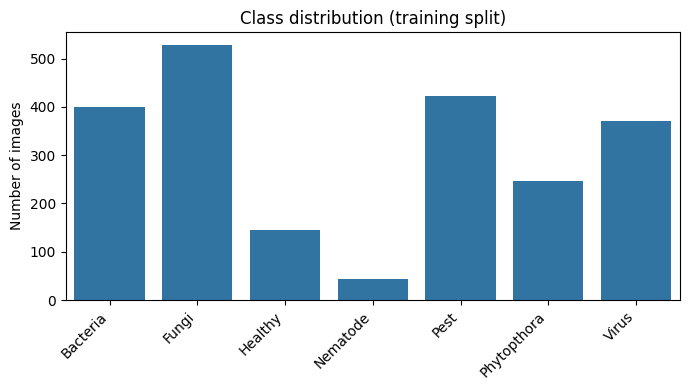

In [9]:
class_counts = np.zeros(NUM_CLASSES)
for _, labels in train_ds.unbatch():
    class_counts[int(labels.numpy())] += 1

for name, count in zip(class_names, class_counts):
    print(f"{name:15s}: {int(count)}")

total = class_counts.sum()
class_weights = total / (NUM_CLASSES * class_counts)
class_weights_dict = {i: w for i, w in enumerate(class_weights)}
print("\nClass weights:", class_weights_dict)

plt.figure(figsize=(7, 4))
sns.barplot(x=class_names, y=class_counts)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Number of images")
plt.title("Class distribution (training split)")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/class_distribution.png", dpi=150)
plt.show()

## 5. Data Augmentation

In [10]:
# [CHANGED] Mild, realistic augmentation. It lives inside the model, so it is ACTIVE ONLY DURING TRAINING;
# validation / test / inference receive deterministic preprocessing (Keras random layers are no-ops at inference).
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),                   # leaf orientation is arbitrary in field photos
    layers.RandomRotation(0.05),                                    # +/- 18 degrees (was +/- 72)
    layers.RandomZoom(0.1),                                         # mild zoom (was 0.2)
    layers.RandomTranslation(0.05, 0.05),                           # small shifts
    layers.RandomBrightness(0.1, value_range=(0, 255)),             # moderate brightness change
    layers.RandomContrast(0.1),
], name="data_augmentation")

## 6. Experimental Component #1 — Squeeze-and-Excitation (SE) Attention

The SE block learns a per-channel gate: it squeezes each feature map to a single number (global average pooling), passes it through a small bottleneck MLP, and uses a sigmoid to produce a weight per channel. Those weights rescale the original feature maps.

SE is an **established** module, not a new invention. The *hypothesis* is that it helps the network emphasise lesion-related channels over background clutter in this uncontrolled-environment dataset. That hypothesis is **tested, not assumed**, by the ablation study in Section 10 (EfficientNetV2B0 with and without SE, everything else equal).

In [11]:
def se_block(input_tensor, ratio=16, name="se_block"):
    channels = input_tensor.shape[-1]
    se = layers.GlobalAveragePooling2D(name=f"{name}_gap")(input_tensor)
    se = layers.Dense(max(channels // ratio, 8), activation="relu", name=f"{name}_fc1")(se)
    se = layers.Dense(channels, activation="sigmoid", name=f"{name}_fc2")(se)
    se = layers.Reshape((1, 1, channels), name=f"{name}_reshape")(se)
    return layers.Multiply(name=f"{name}_scale")([input_tensor, se])

## 7. Experimental Component #2 — Class-Balanced Focal Loss

Focal loss down-weights easy, well-classified examples so training concentrates on hard examples. Here it is combined with per-class weights (used as the `alpha` factor). Whether this helps on this dataset is **tested, not assumed**: the ablation study in Section 10 compares focal loss against class-weighted cross-entropy (same backbone, same everything else), and a plain-cross-entropy control run is included as well.

In [12]:
def make_class_balanced_focal_loss(class_weights_vec, gamma=2.0, num_classes=NUM_CLASSES):
    class_weights_vec = tf.constant(class_weights_vec, dtype=tf.float32)

    def loss_fn(y_true, y_pred):
        y_true = tf.cast(y_true, tf.int32)
        y_true_oh = tf.one_hot(y_true, depth=num_classes)
        y_true_oh = tf.reshape(y_true_oh, tf.shape(y_pred))

        eps = tf.keras.backend.epsilon()
        y_pred = tf.clip_by_value(y_pred, eps, 1.0 - eps)

        ce = -y_true_oh * tf.math.log(y_pred)
        modulating_factor = tf.math.pow(1.0 - y_pred, gamma)
        alpha_factor = y_true_oh * class_weights_vec

        loss = alpha_factor * modulating_factor * ce
        return tf.reduce_sum(loss, axis=-1)

    return loss_fn

class_weights_vec = np.array([class_weights_dict[i] for i in range(NUM_CLASSES)], dtype=np.float32)
class_weights_vec = class_weights_vec / class_weights_vec.sum() * NUM_CLASSES  # normalize
focal_loss = make_class_balanced_focal_loss(class_weights_vec, gamma=2.0)

### 7.1 [NEW] Loss settings actually used (and a check for over-weighting minority classes)

In [13]:
print("Class distribution (train):", dict(zip(class_names, class_counts.astype(int))))
print(f"Focal loss: gamma = 2.0 | alpha = class weights normalised to mean 1 -> "
      f"{dict(zip(class_names, np.round(class_weights_vec, 3)))}")
ratio = class_weights_vec.max() / class_weights_vec.min()
print(f"Largest / smallest class weight = {ratio:.1f}x")
if ratio > 10:
    print("WARNING: very large weight ratio - minority classes may be over-weighted.")
print("\nLoss used by each kind of run:")
print("  focal runs         : focal loss with alpha = class weights above; Keras `class_weight` is NOT passed (no double weighting)")
print("  non-focal runs     : sparse categorical cross-entropy + Keras `class_weight` (class-weighted CE)")
print("  PlainCE control run: sparse categorical cross-entropy, no class weights (see Section 10)")

Class distribution (train): {'Bacteria': np.int64(400), 'Fungi': np.int64(528), 'Healthy': np.int64(145), 'Nematode': np.int64(43), 'Pest': np.int64(423), 'Phytopthora': np.int64(247), 'Virus': np.int64(370)}
Focal loss: gamma = 2.0 | alpha = class weights normalised to mean 1 -> {'Bacteria': np.float32(0.401), 'Fungi': np.float32(0.304), 'Healthy': np.float32(1.106), 'Nematode': np.float32(3.728), 'Pest': np.float32(0.379), 'Phytopthora': np.float32(0.649), 'Virus': np.float32(0.433)}
Largest / smallest class weight = 12.3x

Loss used by each kind of run:
  focal runs         : focal loss with alpha = class weights above; Keras `class_weight` is NOT passed (no double weighting)
  non-focal runs     : sparse categorical cross-entropy + Keras `class_weight` (class-weighted CE)
  PlainCE control run: sparse categorical cross-entropy, no class weights (see Section 10)


## 8. Model Factory

One function builds the three selected backbones plus the SE-attention variant of EfficientNetV2B0. Each backbone uses its own correct `preprocess_input` inside the model.

In [14]:
from tensorflow.keras.applications import (
    EfficientNetV2B0, DenseNet121, ResNet50
)
from tensorflow.keras.applications import efficientnet_v2, densenet, resnet50

BACKBONES = {
    "EfficientNetV2B0": (EfficientNetV2B0, efficientnet_v2.preprocess_input),
    "DenseNet121":      (DenseNet121,      densenet.preprocess_input),
    "ResNet50":          (ResNet50,         resnet50.preprocess_input),
}


def build_model(backbone_name, use_attention=False, num_classes=NUM_CLASSES, img_size=IMG_SIZE):
    backbone_cls, preprocess_fn = BACKBONES[backbone_name]

    inputs = layers.Input(shape=img_size + (3,), name="input_image")
    x = data_augmentation(inputs)
    x = layers.Lambda(preprocess_fn, name="preprocess")(x)

    base_model = backbone_cls(include_top=False, weights="imagenet", input_tensor=x)
    base_model.trainable = False

    feat = base_model.output
    if use_attention:
        feat = se_block(feat, ratio=16, name="se_attention")

    x = layers.GlobalAveragePooling2D(name="gap")(feat)
    x = layers.Dropout(0.3, name="dropout")(x)
    x = layers.Dense(128, activation="relu", name="dense_128")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="predictions")(x)

    model_name = backbone_name + ("_SE_Proposed" if use_attention else "_Baseline")
    model = models.Model(inputs, outputs, name=model_name)
    return model, base_model

## 9. Training Routine (two-stage fine-tuning, shared across all models)

**[CHANGED] Every run trains for exactly 50 epochs, with no early stopping.** Stage 1 (5 epochs) trains only the new classification head with the backbone frozen. Stage 2 (45 epochs) unfreezes the last `UNFREEZE_LAST_N` layers of the backbone and continues with a much smaller learning rate (1e-3 then 1e-5). The same recipe is applied identically to every model, so the comparison is fair. A short frozen stage is enough for a 7-class head to get going, which leaves most of the budget for fine-tuning; 5 + 45 is a pre-declared choice, not tuned on the test set.

Per run we save: the **final epoch-50 weights**, the **best-validation weights** (lowest `val_loss` over all 50 epochs, saved separately), the full training history (JSON), parameter counts, training time and the chosen hyper-parameters. `ReduceLROnPlateau` is kept because it never stops training.

In [15]:
import time

class BestValCheckpoint(tf.keras.callbacks.Callback):
    """[CHANGED] Saves the weights of the epoch with the lowest val_loss across BOTH stages.
    It never stops training (so every run still completes all 50 epochs)."""
    def __init__(self, path, state):
        super().__init__(); self.path, self.state = path, state
    def on_epoch_end(self, epoch, logs=None):
        v = (logs or {}).get("val_loss")
        if v is not None and v < self.state["best_val_loss"]:
            self.state["best_val_loss"] = float(v)
            self.state["best_epoch"] = self.state["epochs_done"] + epoch + 1     # 1-based over all 50 epochs
            self.model.save_weights(self.path)


def get_callbacks(best_path, state):
    # [CHANGED] EarlyStopping removed (it would cut training short of 50 epochs).
    return [
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7
        ),
        BestValCheckpoint(best_path, state),
    ]


train_info = {}      # per-run bookkeeping: epochs, timing, parameter counts, checkpoint file names, hyper-parameters


def train_model(backbone_name, use_attention=False, use_focal_loss=False, run_key=None, use_class_weights=True):
    run_key = run_key or f"{backbone_name}_att{int(use_attention)}_focal{int(use_focal_loss)}"
    print(f"\n{'='*70}\nTraining {run_key} | {backbone_name} | attention={use_attention} | focal_loss={use_focal_loss}\n{'='*70}")

    tf.keras.utils.set_random_seed(SEED)           # [CHANGED] same seed for every run
    model, base_model = build_model(backbone_name, use_attention=use_attention)
    loss_fn = focal_loss if use_focal_loss else "sparse_categorical_crossentropy"
    cw = None if (use_focal_loss or not use_class_weights) else class_weights_dict   # focal loss already handles weighting

    state = dict(best_val_loss=np.inf, best_epoch=None, epochs_done=0)
    best_path  = f"{OUTPUT_DIR}/{run_key}_best_val.weights.h5"
    final_path = f"{OUTPUT_DIR}/{run_key}_final_epoch{TOTAL_EPOCHS}.weights.h5"
    t0 = time.time()

    # ---- Stage 1: frozen backbone, train the head ----
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=loss_fn, metrics=["accuracy"])
    history1 = model.fit(
        train_ds, validation_data=val_ds, epochs=EPOCHS_PHASE1,
        callbacks=get_callbacks(best_path, state), class_weight=cw, verbose=1
    )
    state["epochs_done"] = EPOCHS_PHASE1

    # ---- Stage 2: fine-tune last N layers ----
    base_model.trainable = True
    for layer in base_model.layers[:-UNFREEZE_LAST_N]:
        layer.trainable = False

    model.compile(optimizer=tf.keras.optimizers.Adam(1e-5), loss=loss_fn, metrics=["accuracy"])
    history2 = model.fit(
        train_ds, validation_data=val_ds, epochs=EPOCHS_PHASE2,
        callbacks=get_callbacks(best_path, state), class_weight=cw, verbose=1
    )
    train_time = time.time() - t0

    combined_history = {
        k: history1.history.get(k, []) + history2.history.get(k, [])
        for k in set(history1.history) | set(history2.history)
    }
    n_epochs = len(combined_history["loss"])
    assert n_epochs == TOTAL_EPOCHS, f"{run_key}: trained {n_epochs} epochs, expected exactly {TOTAL_EPOCHS}"

    model.save_weights(final_path)                                           # retain final-epoch weights for audit
    # All downstream comparisons/inference use the checkpoint selected on validation loss.
    # The untouched test set must not be used to choose this checkpoint.
    model.load_weights(best_path)
    with open(f"{OUTPUT_DIR}/{run_key}_history.json", "w") as f:
        json.dump({k: [float(x) for x in v] for k, v in combined_history.items()}, f)

    n_trainable = int(sum(np.prod(w.shape) for w in model.trainable_weights))
    n_total = int(model.count_params())
    train_info[run_key] = dict(
        backbone=backbone_name, use_attention=use_attention, use_focal_loss=use_focal_loss,
        use_class_weights=bool(cw is not None), epochs_trained=n_epochs,
        stage_epochs=[EPOCHS_PHASE1, EPOCHS_PHASE2], best_epoch=state["best_epoch"],
        best_val_loss=state["best_val_loss"], train_time_s=train_time,
        params_total=n_total, params_trainable_final_stage=n_trainable, params_non_trainable_final_stage=n_total - n_trainable,
        optimizer="Adam", learning_rates=[1e-3, 1e-5], batch_size=BATCH_SIZE, img_size=list(IMG_SIZE), seed=SEED,
        preprocessing=f"{BACKBONES[backbone_name][1].__module__}.{BACKBONES[backbone_name][1].__name__} (inside model)",
        final_checkpoint=final_path, best_val_checkpoint=best_path,
    )
    return model, combined_history

## 10. Train Focused Model Set

Seven runs are retained: DenseNet121, ResNet50, four EfficientNetV2B0 ablation variants (A/B/C/D), and an optional plain-CE control. EfficientNetB0 was removed because it adds another benchmark without a distinct research question.

| Run key | Backbone | SE attention | Loss | Role |
|---|---|---|---|---|
| `DenseNet121` | DenseNet121 | no | class-weighted CE | baseline |
| `ResNet50` | ResNet50 | no | class-weighted CE | baseline |
| `EfficientNetV2B0_Vanilla` | EfficientNetV2B0 | no | class-weighted CE | ablation A |
| `EfficientNetV2B0_SE` | EfficientNetV2B0 | yes | class-weighted CE | ablation B |
| `EfficientNetV2B0_Focal` | EfficientNetV2B0 | no | class-balanced focal | ablation C |
| `EfficientNetV2B0_Proposed` | EfficientNetV2B0 | yes | class-balanced focal | ablation D |
| `EfficientNetV2B0_PlainCE` | EfficientNetV2B0 | no | plain CE, no weights | loss control |

A/B/C/D isolates the effects of SE attention and focal loss. The untouched test set is reserved for final evaluation.

In [16]:
RUN_PLAIN_CE_CONTROL = True

# Focused model set: two strong baselines + the EfficientNetV2B0 ablation family.
# EfficientNetB0 was removed because it adds another benchmark without answering a new research question.
RUNS = [
    dict(key="DenseNet121",              backbone="DenseNet121",      use_attention=False, use_focal_loss=False),
    dict(key="ResNet50",                 backbone="ResNet50",         use_attention=False, use_focal_loss=False),
    dict(key="EfficientNetV2B0_Vanilla", backbone="EfficientNetV2B0",  use_attention=False, use_focal_loss=False),  # A
    dict(key="EfficientNetV2B0_Proposed",backbone="EfficientNetV2B0",  use_attention=True,  use_focal_loss=True),   # D
    dict(key="EfficientNetV2B0_SE",      backbone="EfficientNetV2B0",  use_attention=True,  use_focal_loss=False),  # B
    dict(key="EfficientNetV2B0_Focal",   backbone="EfficientNetV2B0",  use_attention=False, use_focal_loss=True),   # C
]
if RUN_PLAIN_CE_CONTROL:
    RUNS.append(dict(
        key="EfficientNetV2B0_PlainCE",
        backbone="EfficientNetV2B0",
        use_attention=False,
        use_focal_loss=False,
        use_class_weights=False,
    ))

ABLATION = {
    "A": "EfficientNetV2B0_Vanilla",
    "B": "EfficientNetV2B0_SE",
    "C": "EfficientNetV2B0_Focal",
    "D": "EfficientNetV2B0_Proposed",
}

trained_models = {}
histories = {}

for run in RUNS:
    model, history = train_model(
        run["backbone"],
        use_attention=run["use_attention"],
        use_focal_loss=run["use_focal_loss"],
        run_key=run["key"],
        use_class_weights=run.get("use_class_weights", True),
    )
    trained_models[run["key"]] = model
    histories[run["key"]] = history

# Inference latency is retained because practical deployment cost is part of model selection.
_xb, _ = next(iter(val_ds))
for k, m in trained_models.items():
    m.predict(_xb, verbose=0)
    _t = time.time()
    for _ in range(3):
        m.predict(_xb, verbose=0)
    train_info[k]["latency_ms_per_image"] = (time.time() - _t) / 3 / len(_xb) * 1000

with open(f"{OUTPUT_DIR}/train_info.json", "w") as f:
    json.dump(train_info, f, indent=2)

display(pd.DataFrame(train_info).T[
    ["epochs_trained", "best_epoch", "train_time_s", "params_total",
     "params_trainable_final_stage", "latency_ms_per_image"]
].round(2))


Training DenseNet121 | DenseNet121 | attention=False | focal_loss=False
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
68/68 ━━━━━━━━━━━━━━━━━━━━ 37s 279ms/step - accuracy: 0.3159 - loss: 1.6581 - val_accuracy: 0.4739 - val_loss: 1.3383 - learning_rate: 0.0010
Epoch 2/5
68/68 ━━━━━━━━━━━━━━━━━━━━ 13s 193ms/step - accuracy: 0.4750 - loss: 1.2723 - val_accuracy: 0.5304 - val_loss: 1.2496 - learning_rate: 0.0010
Epoch 3/5
68/68 ━━━━━━━━━━━━━━━━━━━━ 14s 205ms/step - accuracy: 0.5079 - loss: 1.1786 - val_accuracy: 0.5196 - val_loss: 1.1279 - learning_rate: 0.0010
Epoch 4/5
68/68 ━━━━━━━━━━━━━━━━━━━━ 13s 185ms/step - accuracy: 0.5380 - loss: 1.0747 - val_accuracy: 0.5543 - val_loss: 1.1726 - learning_rate: 0.0010
Epoch 5/5
68/68 ━━━━━━━━━━━━━━━━━━━━ 15s 221ms/step - accuracy: 0.5468 - loss: 1.0918 - val_accuracy: 0.5696 - val_loss: 1.1119 - learning_rate: 0.0010
Epoch 1/45
68/68 ━━━━━━━━━━━━━━━━━━━━ 36s 273ms/step - accuracy: 0.5385 - loss: 1.1256 - val_accuracy: 0.5848 - val_

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 62 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


,epochs_trained,best_epoch,train_time_s,params_total,params_trainable_final_stage,latency_ms_per_image
DenseNet121,50,6,722.982759,7169607,773511,6.820289
ResNet50,50,21,783.308646,23850887,14713351,6.070599
EfficientNetV2B0_Vanilla,50,39,369.950492,6084183,1328743,4.591425
EfficientNetV2B0_Proposed,50,44,379.524574,6290343,1534903,4.434563
EfficientNetV2B0_SE,50,45,376.717735,6290343,1534903,4.499438
EfficientNetV2B0_Focal,50,44,387.635102,6084183,1328743,4.564372
EfficientNetV2B0_PlainCE,50,5,383.054051,6084183,1328743,4.674534


## 11. Evaluation on the Held-Out Test Set

Accuracy, macro-precision/recall/F1, and macro one-vs-rest ROC-AUC — the standard metric set reviewers expect for a multi-class comparison table.


In [17]:
from sklearn.metrics import balanced_accuracy_score

def evaluate_model(model, test_ds, num_classes=NUM_CLASSES):
    y_true, y_pred_probs = [], []
    for images, labels in test_ds:
        probs = model.predict(images, verbose=0)
        y_pred_probs.append(probs)
        y_true.append(labels.numpy())

    y_true = np.concatenate(y_true)
    y_pred_probs = np.concatenate(y_pred_probs)
    y_pred = np.argmax(y_pred_probs, axis=1)

    y_true_oh = np.eye(num_classes)[y_true]

    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0),      # [CHANGED] added
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),                        # [CHANGED] added
        "roc_auc_macro": roc_auc_score(y_true_oh, y_pred_probs, average="macro", multi_class="ovr"),
    }
    return metrics, y_true, y_pred, y_pred_probs


results = {}
predictions = {}

for key, model in trained_models.items():
    metrics, y_true, y_pred, y_pred_probs = evaluate_model(model, test_ds)
    # [CHANGED] validation macro-F1 is stored so the "best" model can be chosen WITHOUT looking at the test set
    metrics["val_f1_macro"] = evaluate_model(model, val_ds)[0]["f1_macro"]
    results[key] = metrics
    predictions[key] = dict(y_true=y_true, y_pred=y_pred, y_pred_probs=y_pred_probs)
    print(key, metrics)

DenseNet121 {'accuracy': 0.5956521739130435, 'precision_macro': 0.6087525482984534, 'recall_macro': 0.6902157635769599, 'f1_macro': 0.5885107553029922, 'f1_weighted': 0.6058680376803626, 'balanced_accuracy': np.float64(0.6902157635769599), 'roc_auc_macro': np.float64(0.9138940185146655), 'val_f1_macro': 0.5950104268328454}
ResNet50 {'accuracy': 0.7760869565217391, 'precision_macro': 0.7660012438583598, 'recall_macro': 0.8043598707922962, 'f1_macro': 0.7730452937922544, 'f1_weighted': 0.7782823112492113, 'balanced_accuracy': np.float64(0.8043598707922962), 'roc_auc_macro': np.float64(0.9617069747876219), 'val_f1_macro': 0.7727144910892115}
EfficientNetV2B0_Vanilla {'accuracy': 0.6456521739130435, 'precision_macro': 0.6716867396809116, 'recall_macro': 0.7021416095111331, 'f1_macro': 0.6529292951226859, 'f1_weighted': 0.6538763991819697, 'balanced_accuracy': np.float64(0.7021416095111331), 'roc_auc_macro': np.float64(0.9230276679747229), 'val_f1_macro': 0.665494302904655}
EfficientNetV2B0

In [18]:
results_df = pd.DataFrame(results).T
# [CHANGED] columns for the final comparison table: epochs and training time
results_df["epochs"] = [train_info[k]["epochs_trained"] for k in results_df.index]
results_df["train_time_min"] = [train_info[k]["train_time_s"] / 60 for k in results_df.index]
# [CHANGED] sorted by VALIDATION macro-F1 (not test), so results_df.index[0] is a validation-selected model
results_df = results_df.sort_values("val_f1_macro", ascending=False)
results_df = results_df.round(4)
results_df.to_csv(f"{OUTPUT_DIR}/model_comparison.csv")
results_df

,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,balanced_accuracy,roc_auc_macro,val_f1_macro,epochs,train_time_min
ResNet50,0.7761,0.7660,0.8044,0.7730,0.7783,0.8044,0.9617,0.7727,50,13.0551
EfficientNetV2B0_SE,0.7000,0.7123,0.7336,0.7055,0.7070,0.7336,0.9412,0.7229,50,6.2786
EfficientNetV2B0_Focal,0.6913,0.6895,0.7148,0.6860,0.7026,0.7148,0.9340,0.7026,50,6.4606
EfficientNetV2B0_Vanilla,0.6457,0.6717,0.7021,0.6529,0.6539,0.7021,0.9230,0.6655,50,6.1658
EfficientNetV2B0_Proposed,0.6370,0.6739,0.6683,0.6508,0.6479,0.6683,0.9259,0.6564,50,6.3254
EfficientNetV2B0_PlainCE,0.6978,0.7031,0.6959,0.6810,0.7081,0.6959,0.9422,0.6274,50,6.3842
DenseNet121,0.5957,0.6088,0.6902,0.5885,0.6059,0.6902,0.9139,0.5950,50,12.0497


## 12. Visual Comparison — Accuracy & F1 Across Models

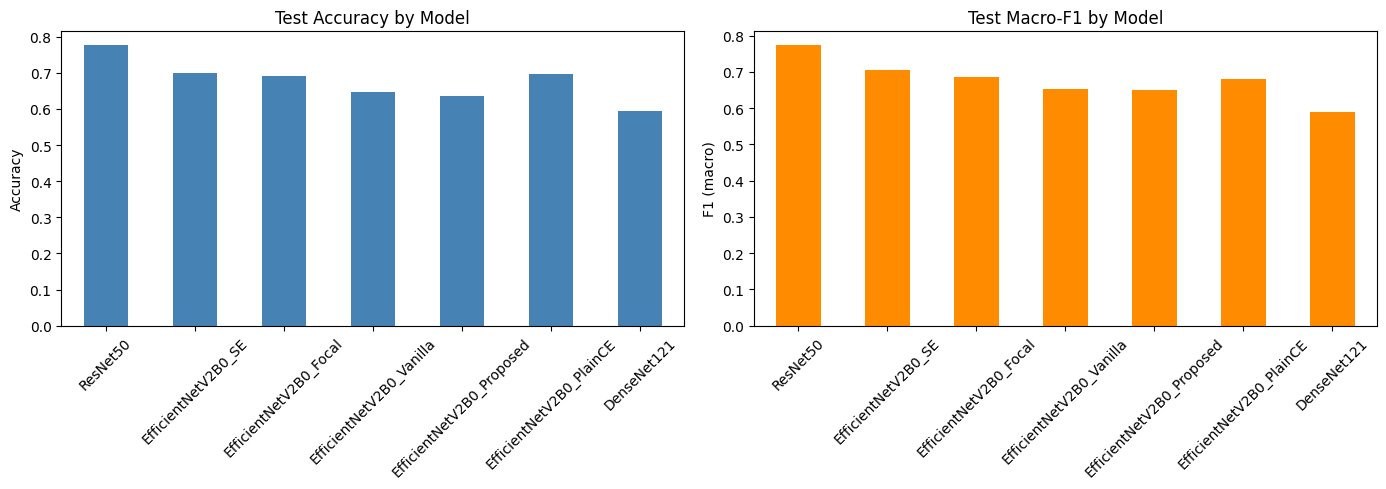

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

results_df["accuracy"].plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Test Accuracy by Model")
axes[0].set_ylabel("Accuracy")
axes[0].tick_params(axis='x', rotation=45)

results_df["f1_macro"].plot(kind="bar", ax=axes[1], color="darkorange")
axes[1].set_title("Test Macro-F1 by Model")
axes[1].set_ylabel("F1 (macro)")
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/accuracy_f1_comparison.png", dpi=150)
plt.show()

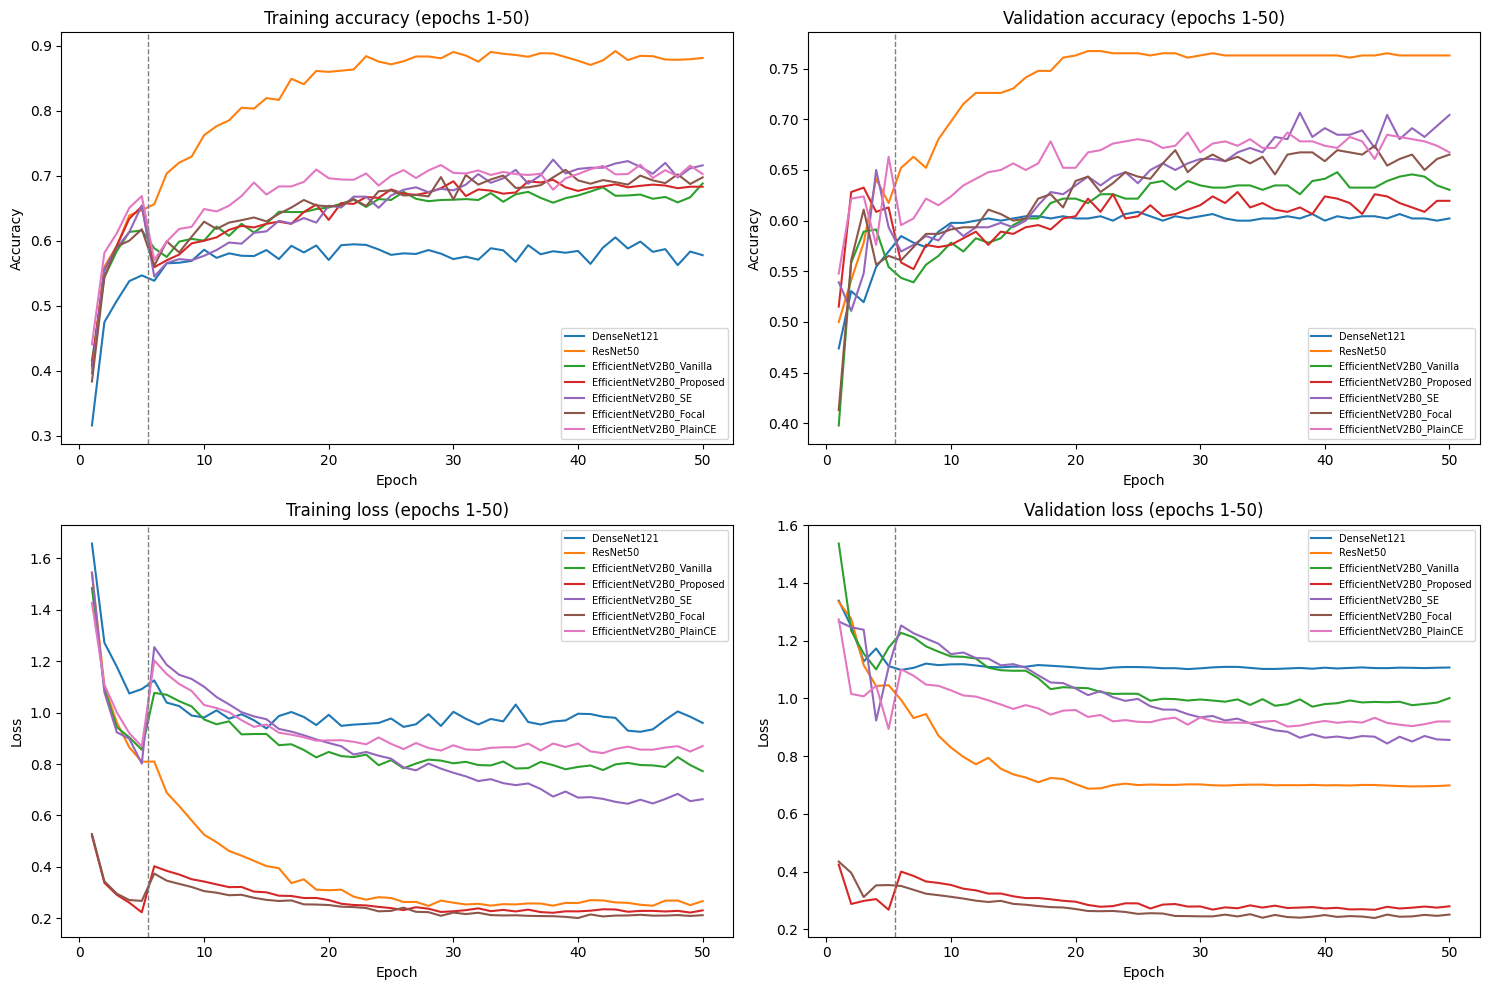

In [20]:
# [CHANGED] training AND validation curves, accuracy AND loss, over all 50 epochs (dashed line = head-only -> fine-tuning)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
panels = [("accuracy", "Training accuracy"), ("val_accuracy", "Validation accuracy"),
          ("loss", "Training loss"), ("val_loss", "Validation loss")]
for ax, (metric, title) in zip(axes.ravel(), panels):
    for key, hist in histories.items():
        ax.plot(range(1, len(hist[metric]) + 1), hist[metric], label=key)
    ax.axvline(EPOCHS_PHASE1 + 0.5, color="gray", ls="--", lw=1)
    ax.set_title(f"{title} (epochs 1-{TOTAL_EPOCHS})"); ax.set_xlabel("Epoch"); ax.set_ylabel(title.split()[-1].capitalize())
    ax.legend(fontsize=7)

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/training_curves.png", dpi=150)
plt.show()

### 12.1 [NEW] Did validation performance converge by epoch 50?

A simple, pre-declared heuristic: compare the mean validation loss of epochs 41-45 with epochs 46-50. If it is still falling by more than 0.02, the run is flagged as **possibly not converged** (a limitation to report, not a reason to train longer).

## 13. Confusion Matrices

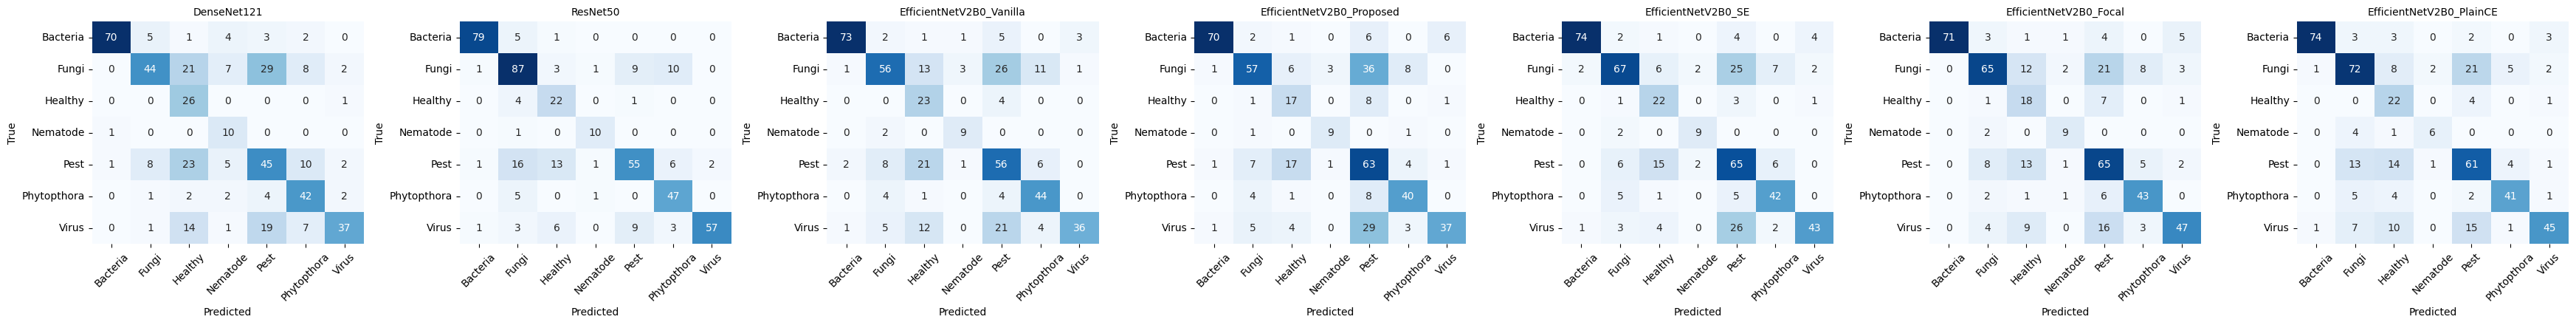

In [21]:
n_models = len(predictions)
fig, axes = plt.subplots(1, n_models, figsize=(5 * n_models, 4.5))
if n_models == 1:
    axes = [axes]

for ax, (key, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(pred["y_true"], pred["y_pred"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=class_names, yticklabels=class_names, cbar=False)
    ax.set_title(key, fontsize=10)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/confusion_matrices.png", dpi=150)
plt.show()

In [22]:
best_key = results_df.index[0]
print(f"Best model: {best_key}\n")
print(classification_report(
    predictions[best_key]["y_true"], predictions[best_key]["y_pred"], target_names=class_names
))

Best model: ResNet50

              precision    recall  f1-score   support

    Bacteria       0.96      0.93      0.95        85
       Fungi       0.72      0.78      0.75       111
     Healthy       0.49      0.81      0.61        27
    Nematode       0.77      0.91      0.83        11
        Pest       0.74      0.59      0.65        94
 Phytopthora       0.71      0.89      0.79        53
       Virus       0.97      0.72      0.83        79

    accuracy                           0.78       460
   macro avg       0.77      0.80      0.77       460
weighted avg       0.80      0.78      0.78       460



### 13.1 [NEW] Healthy / diseased errors, Pest and minority-class recall (all models, test set)

Accuracy alone hides the mistakes that matter most for a farmer: a diseased leaf called *Healthy*, or a healthy leaf called diseased. Counts are on a small test set (see the class sizes), so treat single-image differences as noise.

In [23]:
h, pest, nem = (class_names.index(c) for c in ["Healthy", "Pest", "Nematode"])
rows = {}
for key, pr in predictions.items():
    yt, yp = pr["y_true"], pr["y_pred"]
    rec = lambda c: float(np.mean(yp[yt == c] == c))
    rows[key] = {
        "Healthy called diseased (rate)":  float(np.mean(yp[yt == h] != h)),
        "Diseased called Healthy (rate)":  float(np.mean(yp[yt != h] == h)),
        "Pest recall":                     rec(pest),
        "Nematode recall":                 rec(nem),
        "Healthy recall":                  rec(h),
        "mean recall of Nematode+Healthy": (rec(nem) + rec(h)) / 2,
        "balanced accuracy":               float(results[key]["balanced_accuracy"]),
    }
err_df = pd.DataFrame(rows).T.round(3)
err_df.to_csv(f"{OUTPUT_DIR}/error_profile.csv")
print(f"Test images: Healthy={int((test_y == h).sum())}, Pest={int((test_y == pest).sum())}, Nematode={int((test_y == nem).sum())}")
err_df

Test images: Healthy=27, Pest=94, Nematode=11


,Healthy called diseased (rate),Diseased called Healthy (rate),Pest recall,Nematode recall,Healthy recall,mean recall of Nematode+Healthy,balanced accuracy
DenseNet121,0.037,0.141,0.479,0.909,0.963,0.936,0.690
ResNet50,0.185,0.053,0.585,0.909,0.815,0.862,0.804
EfficientNetV2B0_Vanilla,0.148,0.111,0.596,0.818,0.852,0.835,0.702
EfficientNetV2B0_Proposed,0.370,0.067,0.670,0.818,0.630,0.724,0.668
EfficientNetV2B0_SE,0.185,0.062,0.691,0.818,0.815,0.816,0.734
EfficientNetV2B0_Focal,0.333,0.083,0.691,0.818,0.667,0.742,0.715
EfficientNetV2B0_PlainCE,0.185,0.092,0.649,0.545,0.815,0.680,0.696


### 13.2 [NEW] Final epoch-50 checkpoint vs best-validation checkpoint

The main CNN comparison in this notebook uses the **best-validation** weights (lowest `val_loss` over 50 epochs), restored at the end of each training run. The **final epoch-50** weights are saved separately for audit; there is no additional checkpoint-comparison execution cell here. The best-validation epoch was chosen on validation data; the test set is not used to pick between the two.

## 14. Interpretability — Grad-CAM

Grad-CAM highlights the regions that influenced the model's decision. It is used here to **look at** whether the vanilla and SE+focal EfficientNetV2B0 models focus on lesions or on background. A heatmap is **not proof** that a model is accurate or that attention helps; it is a qualitative sanity check that has to be read together with the ablation and significance results.

In [24]:
def find_last_conv_layer(model):
    # Picks the last layer with a 4-D (batch, H, W, channels) output. This is looked up per model, so it works for
    # EfficientNet ('top_activation'), ResNet50, DenseNet121 and the SE variant ('se_attention_scale').
    for layer in reversed(model.layers):
        if len(layer.output.shape) == 4:  # [CHANGED] Keras 3 has no layer.output_shape
            return layer.name
    raise ValueError("No 4D (conv-like) layer found")


def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    grad_model = tf.keras.Model(
        model.inputs, [model.get_layer(last_conv_layer_name).output, model.output]
    )
    img_array = tf.convert_to_tensor(img_array, dtype=tf.float32)
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model([img_array])   # [CHANGED] list matches the model's input structure (removes the warning)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), int(pred_index)


def overlay_gradcam(image, heatmap, alpha=0.4):
    heatmap = tf.image.resize(heatmap[..., tf.newaxis], IMG_SIZE).numpy().squeeze()
    heatmap = np.uint8(255 * heatmap)
    jet = plt.get_cmap("jet")
    jet_colors = jet(np.arange(256))[:, :3]
    jet_heatmap = jet_colors[heatmap]
    overlay = jet_heatmap * alpha + (image / 255.0) * (1 - alpha)
    return np.clip(overlay, 0, 1)

Proposed model last conv layer: se_attention_scale
Vanilla model last conv layer: top_activation


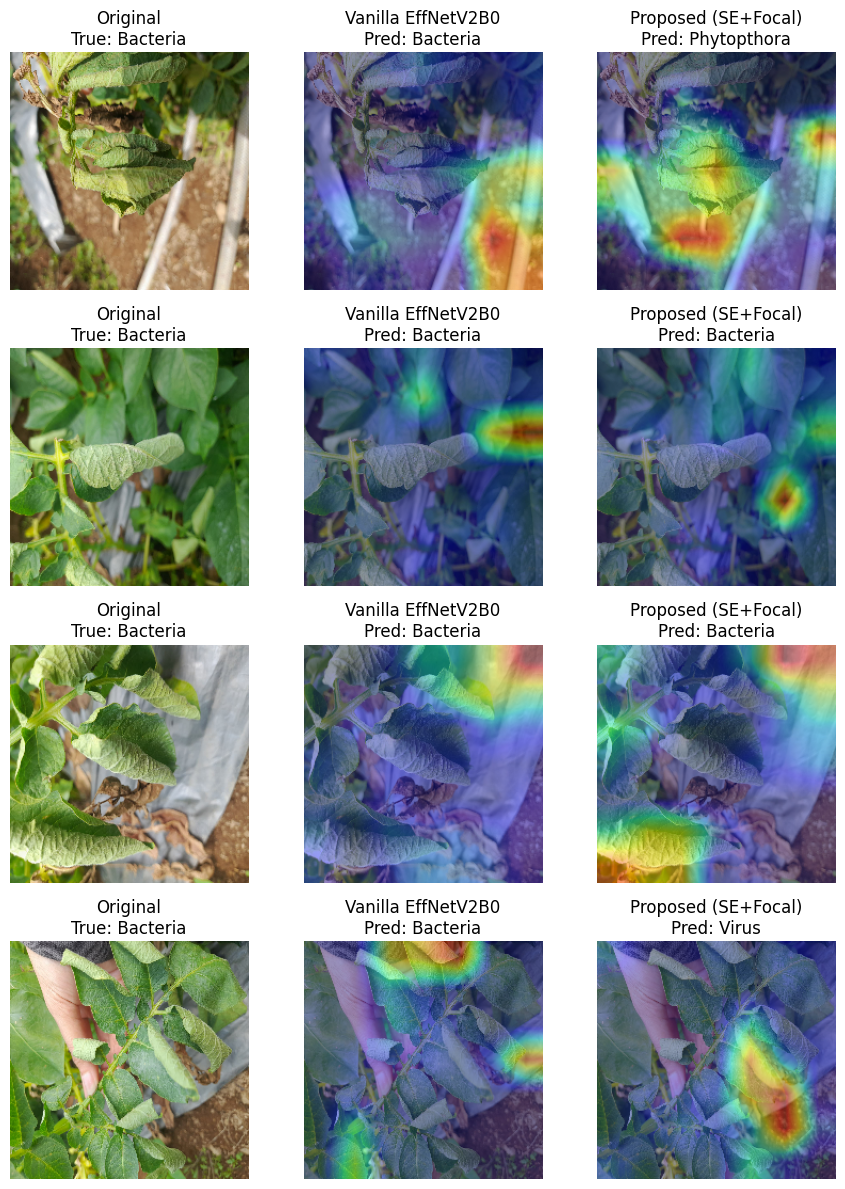

In [25]:
proposed_model = trained_models["EfficientNetV2B0_Proposed"]
vanilla_model = trained_models["EfficientNetV2B0_Vanilla"]

last_conv_proposed = find_last_conv_layer(proposed_model)
last_conv_vanilla = find_last_conv_layer(vanilla_model)
print("Proposed model last conv layer:", last_conv_proposed)
print("Vanilla model last conv layer:", last_conv_vanilla)

sample_images, sample_labels = next(iter(test_ds.take(1)))
n_show = min(4, sample_images.shape[0])

fig, axes = plt.subplots(n_show, 3, figsize=(9, 3 * n_show))

for i in range(n_show):
    img = sample_images[i].numpy()
    img_batch = np.expand_dims(img, axis=0)
    true_label = class_names[int(sample_labels[i])]

    heatmap_p, pred_p = make_gradcam_heatmap(img_batch, proposed_model, last_conv_proposed)
    heatmap_v, pred_v = make_gradcam_heatmap(img_batch, vanilla_model, last_conv_vanilla)

    axes[i, 0].imshow(img.astype("uint8"))
    axes[i, 0].set_title(f"Original\nTrue: {true_label}")
    axes[i, 1].imshow(overlay_gradcam(img, heatmap_v))
    axes[i, 1].set_title(f"Vanilla EffNetV2B0\nPred: {class_names[pred_v]}")
    axes[i, 2].imshow(overlay_gradcam(img, heatmap_p))
    axes[i, 2].set_title(f"Proposed (SE+Focal)\nPred: {class_names[pred_p]}")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/gradcam_comparison.png", dpi=150)
plt.show()

### 14.1 [NEW] Grad-CAM on selected cases: correct vs misclassified, Healthy and two disease classes

For Healthy, Pest and Fungi, one image the **proposed** model got right and one it got wrong (first match in test order, not hand-picked by appearance). Columns: original, vanilla EfficientNetV2B0, proposed (SE+Focal), and the strongest individual model *selected on validation macro-F1*. Each heatmap is checked to be non-degenerate before plotting. Read these as qualitative evidence only.

Grad-CAM target layers: {'Vanilla EffNetV2B0': 'top_activation', 'Proposed (SE+Focal)': 'se_attention_scale', 'Strongest: ResNet50': 'conv5_block3_out'}


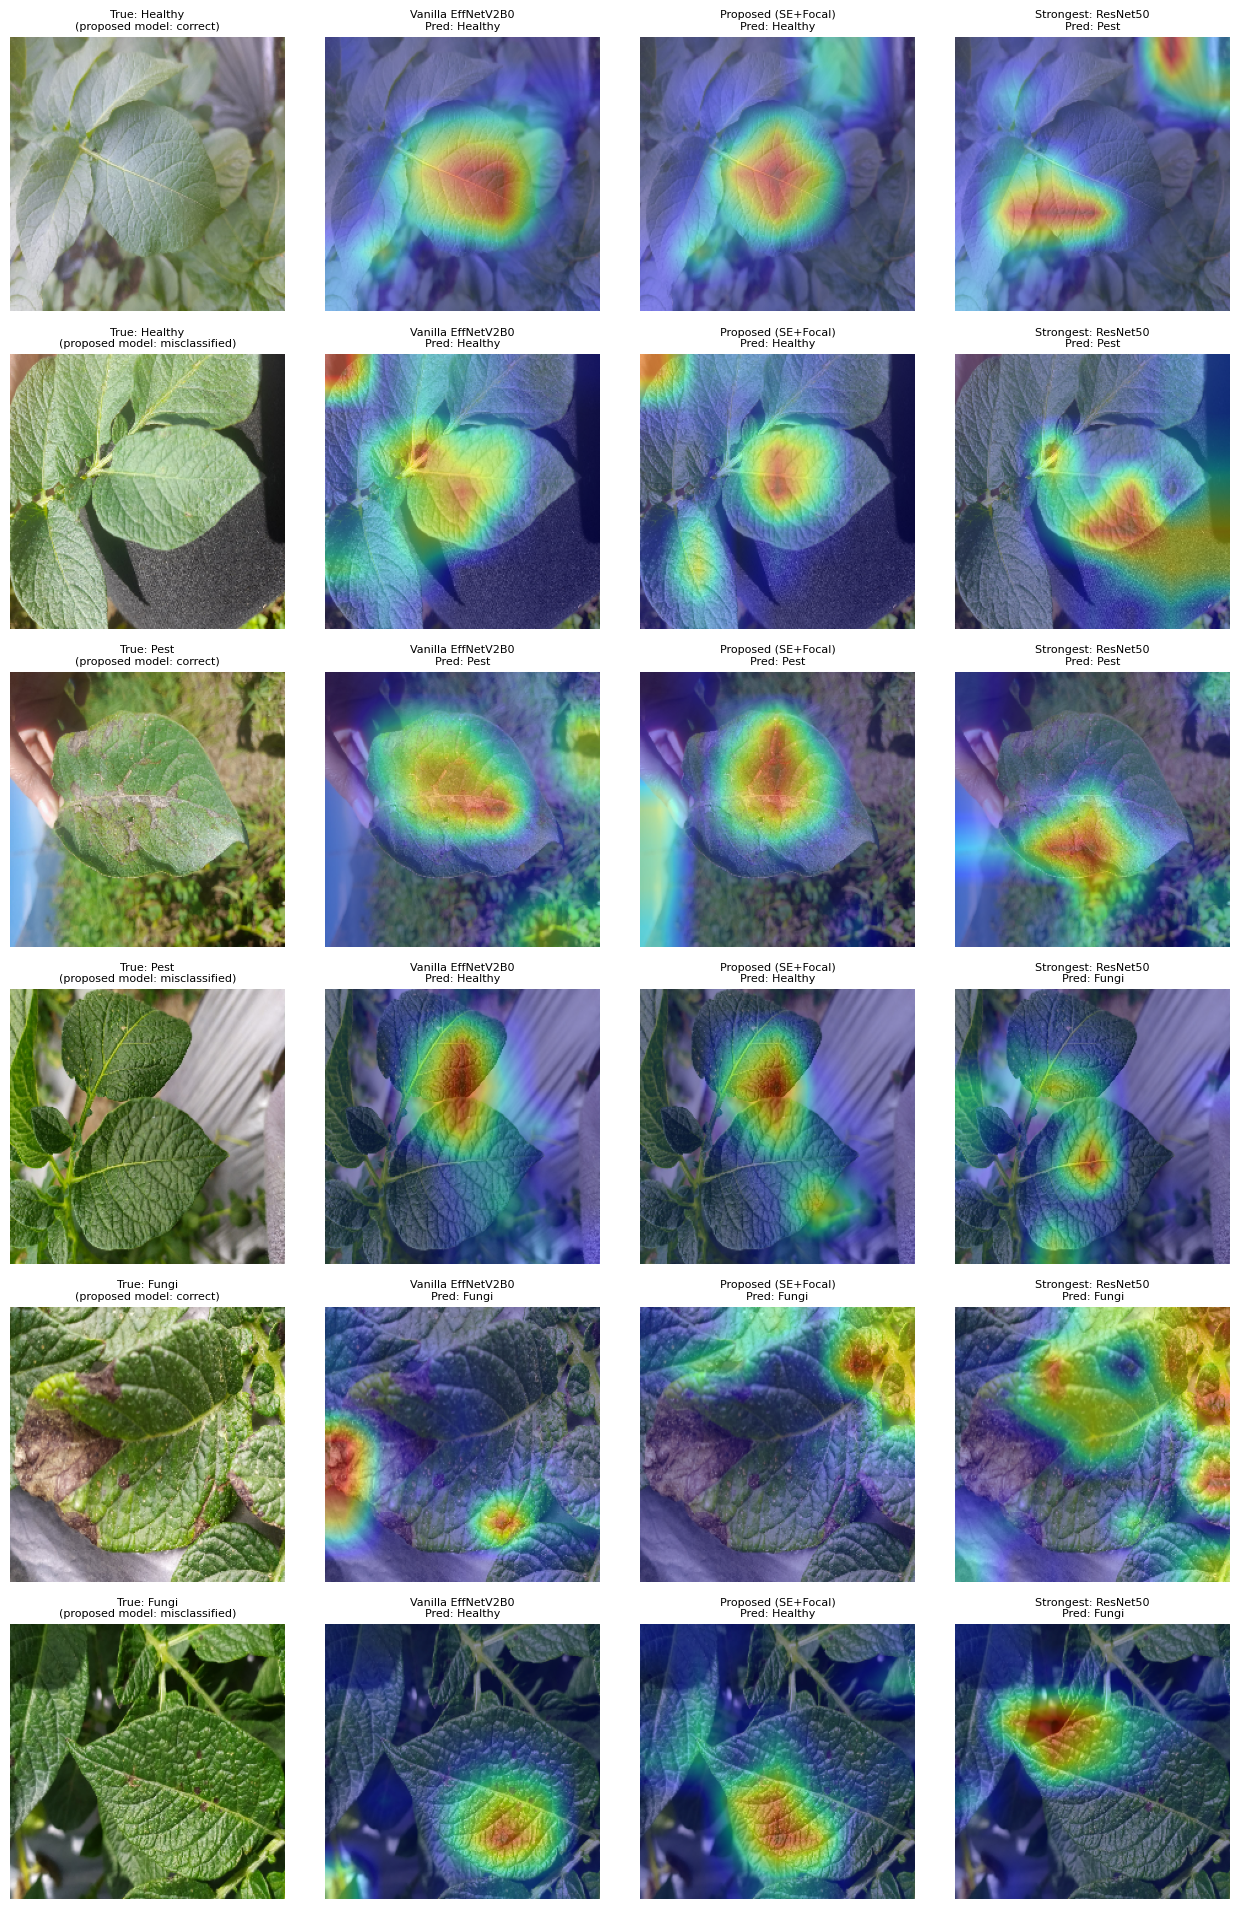

In [26]:
strongest_key = results_df.index[0]                      # chosen by validation macro-F1 (see results_df)
cam_models = {"Vanilla EffNetV2B0": trained_models["EfficientNetV2B0_Vanilla"],
              "Proposed (SE+Focal)": trained_models["EfficientNetV2B0_Proposed"]}
if strongest_key not in ("EfficientNetV2B0_Vanilla", "EfficientNetV2B0_Proposed"):
    cam_models[f"Strongest: {strongest_key}"] = trained_models[strongest_key]
cam_layers = {n: find_last_conv_layer(m) for n, m in cam_models.items()}
print("Grad-CAM target layers:", cam_layers)

yt_all = predictions["EfficientNetV2B0_Proposed"]["y_true"]
yp_prop = predictions["EfficientNetV2B0_Proposed"]["y_pred"]
cases = []
for cname in ["Healthy", "Pest", "Fungi"]:
    c = class_names.index(cname)
    ok, bad = np.where((yt_all == c) & (yp_prop == c))[0], np.where((yt_all == c) & (yp_prop != c))[0]
    if len(ok):  cases.append((int(ok[0]),  "correct"))
    if len(bad): cases.append((int(bad[0]), "misclassified"))

fig, axes = plt.subplots(len(cases), 1 + len(cam_models), figsize=(3.2 * (1 + len(cam_models)), 3.2 * len(cases)))
axes = np.atleast_2d(axes)
for r, (idx, tag) in enumerate(cases):
    img = _load(test_p[idx], 0)[0].numpy().astype("float32")        # same loader as the pipeline, raw 0-255 pixels
    axes[r, 0].imshow(img.astype("uint8"))
    axes[r, 0].set_title(f"True: {class_names[int(yt_all[idx])]}\n(proposed model: {tag})", fontsize=8)
    for c, (name, m) in enumerate(cam_models.items(), start=1):
        hm, pred = make_gradcam_heatmap(img[None], m, cam_layers[name])
        assert np.isfinite(hm).all() and hm.max() > 0, f"degenerate heatmap for {name}"
        axes[r, c].imshow(overlay_gradcam(img, hm))
        axes[r, c].set_title(f"{name}\nPred: {class_names[pred]}", fontsize=8)
    for ax in axes[r]:
        ax.axis("off")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/gradcam_selected_cases.png", dpi=150)
plt.show()

## 15. Statistical Significance — McNemar's Test

Is the proposed model's improvement over the best baseline actually significant, or could it be noise from a single training run? McNemar's test compares the two models' *disagreements* on the same test set — the standard test for comparing two classifiers on paired predictions.


In [27]:
baseline_key = "EfficientNetV2B0_Vanilla"   # [CHANGED] same backbone => isolates the SE+Focal effect (best-baseline comparison: change this key)
proposed_key = "EfficientNetV2B0_Proposed"

y_true = predictions[proposed_key]["y_true"]
correct_proposed = (predictions[proposed_key]["y_pred"] == y_true)
correct_baseline = (predictions[baseline_key]["y_pred"] == y_true)

both_correct = np.sum(correct_proposed & correct_baseline)
only_proposed_correct = np.sum(correct_proposed & ~correct_baseline)
only_baseline_correct = np.sum(~correct_proposed & correct_baseline)
both_wrong = np.sum(~correct_proposed & ~correct_baseline)

contingency_table = [[both_correct, only_proposed_correct],
                     [only_baseline_correct, both_wrong]]

print(f"Comparing: {proposed_key}  vs  {baseline_key}")
print("Contingency table [[both correct, only proposed correct], [only baseline correct, both wrong]]:")
print(np.array(contingency_table))

result = mcnemar(contingency_table, exact=True)
print(f"\nMcNemar's test statistic: {result.statistic:.4f}")
print(f"p-value: {result.pvalue:.4f}")
if result.pvalue >= 0.05:
    print("=> Difference is not statistically significant at p < 0.05")
elif only_proposed_correct > only_baseline_correct:
    print("=> Proposed is significantly BETTER (p < 0.05)")
else:
    print("=> Proposed is significantly WORSE (p < 0.05)")

Comparing: EfficientNetV2B0_Proposed  vs  EfficientNetV2B0_Vanilla
Contingency table [[both correct, only proposed correct], [only baseline correct, both wrong]]:
[[267  26]
 [ 30 137]]

McNemar's test statistic: 26.0000
p-value: 0.6889
=> Difference is not statistically significant at p < 0.05


### 15.1 [NEW] Ablation study: does SE attention, focal loss, or their combination actually help?

All four EfficientNetV2B0 configurations (A: neither, B: +SE, C: +Focal, D: +SE+Focal) share the same split, input size, augmentation, 5+45 epoch schedule, optimizer and learning rates. Each variant is compared with its baseline using exact McNemar on the same test images and a paired bootstrap for the macro-F1 difference. The five p-values are corrected together with the **Holm** method. Verdict wording is computed from the numbers, not pre-written.

In [28]:
from statsmodels.stats.multitest import multipletests

yt = predictions[ABLATION["A"]]["y_true"]
cfg = {"A": ("no", "no"), "B": ("yes", "no"), "C": ("no", "yes"), "D": ("yes", "yes")}
abl_tbl = pd.DataFrame({
    f"{k}: {ABLATION[k]}": {"SE": cfg[k][0], "Focal": cfg[k][1],
                            "val_macro_F1": results_df.loc[ABLATION[k], "val_f1_macro"],
                            "test_accuracy": results_df.loc[ABLATION[k], "accuracy"],
                            "test_macro_F1": results_df.loc[ABLATION[k], "f1_macro"],
                            "test_balanced_acc": results_df.loc[ABLATION[k], "balanced_accuracy"]}
    for k in "ABCD"}).T
print("Ablation table (all 50 epochs, best-validation weights):")
display(abl_tbl)
if "EfficientNetV2B0_PlainCE" in results_df.index:
    print("Loss control, plain CE (no class weights), test macro-F1:", results_df.loc["EfficientNetV2B0_PlainCE", "f1_macro"],
          "| class-weighted CE (A):", results_df.loc[ABLATION["A"], "f1_macro"])

def _macro_f1(t, p):
    return f1_score(t, p, average="macro", zero_division=0)

def _boot_ci(y, pv, pb, n_boot=2000, seed=SEED):
    rng = np.random.default_rng(seed); d = np.empty(n_boot)
    for b in range(n_boot):
        i = rng.integers(0, len(y), len(y)); d[b] = _macro_f1(y[i], pv[i]) - _macro_f1(y[i], pb[i])
    return np.percentile(d, [2.5, 97.5])

comparisons = [("A", "B", "effect of SE alone"), ("A", "C", "effect of focal loss alone"),
               ("A", "D", "SE + focal together"), ("B", "D", "adding focal on top of SE"),
               ("C", "D", "adding SE on top of focal")]
rows = []
for base, var, meaning in comparisons:
    pb, pv = predictions[ABLATION[base]]["y_pred"], predictions[ABLATION[var]]["y_pred"]
    cb, cv = pb == yt, pv == yt
    only_v, only_b = int(np.sum(cv & ~cb)), int(np.sum(~cv & cb))
    p = mcnemar([[int(np.sum(cv & cb)), only_v], [only_b, int(np.sum(~cv & ~cb))]], exact=True).pvalue
    lo, hi = _boot_ci(yt, pv, pb)
    rows.append(dict(comparison=f"{var} vs {base}", meaning=meaning,
                     d_accuracy=accuracy_score(yt, pv) - accuracy_score(yt, pb),
                     d_macro_F1=_macro_f1(yt, pv) - _macro_f1(yt, pb), d_macro_F1_ci_low=lo, d_macro_F1_ci_high=hi,
                     only_variant_correct=only_v, only_baseline_correct=only_b, mcnemar_p=p))
abl_cmp = pd.DataFrame(rows).set_index("comparison")
abl_cmp["mcnemar_p_holm"] = multipletests(abl_cmp["mcnemar_p"].values, method="holm")[1]

def _verdict(r):
    if r["mcnemar_p_holm"] < 0.05:
        return "significant gain" if r["d_accuracy"] > 0 else "significant loss"
    if r["d_macro_F1"] > 0:
        return "numerically higher, NOT significant"
    return "no gain (numerically lower or equal), not significant"
abl_cmp["verdict"] = abl_cmp.apply(_verdict, axis=1)
abl_cmp.round(4).to_csv(f"{OUTPUT_DIR}/ablation_comparison.csv")
abl_cmp.round(4)

Ablation table (all 50 epochs, best-validation weights):


,SE,Focal,val_macro_F1,test_accuracy,test_macro_F1,test_balanced_acc
A: EfficientNetV2B0_Vanilla,no,no,0.6655,0.6457,0.6529,0.7021
B: EfficientNetV2B0_SE,yes,no,0.7229,0.7,0.7055,0.7336
C: EfficientNetV2B0_Focal,no,yes,0.7026,0.6913,0.686,0.7148
D: EfficientNetV2B0_Proposed,yes,yes,0.6564,0.637,0.6508,0.6683


Loss control, plain CE (no class weights), test macro-F1: 0.681 | class-weighted CE (A): 0.6529


,meaning,d_accuracy,d_macro_F1,d_macro_F1_ci_low,d_macro_F1_ci_high,only_variant_correct,only_baseline_correct,mcnemar_p,mcnemar_p_holm,verdict
comparison,,,,,,,,,,
B vs A,effect of SE alone,0.0543,0.0526,0.0218,0.0846,39,14,0.0008,0.0032,significant gain
C vs A,effect of focal loss alone,0.0457,0.0331,0.0010,0.0652,39,18,0.0075,0.0150,significant gain
D vs A,SE + focal together,-0.0087,-0.0022,-0.0321,0.0299,26,30,0.6889,0.6889,"no gain (numerically lower or equal), not sign..."
D vs B,adding focal on top of SE,-0.0630,-0.0548,-0.0806,-0.0290,5,34,0.0000,0.0000,significant loss
D vs C,adding SE on top of focal,-0.0543,-0.0353,-0.0676,0.0003,17,42,0.0015,0.0046,significant loss


## 16. Robustness / Stress Testing — Does the Model Survive Image Changes?

The held-out test set is never used to tune the model. We create controlled perturbations **only for evaluation**:
brightness, contrast, blur, Gaussian noise, and a combined perturbation.

**Research question:** which model loses the least macro-F1 when image quality or illumination changes?

condition,blur,brightness,clean,combined,contrast,noise
model,,,,,,
DenseNet121,0.5549,0.5667,0.5885,0.4116,0.5386,0.4810
EfficientNetV2B0_Proposed,0.5953,0.6475,0.6508,0.5150,0.6377,0.5928
EfficientNetV2B0_Vanilla,0.6001,0.6399,0.6529,0.5301,0.6468,0.5452
ResNet50,0.7604,0.7733,0.7727,0.5702,0.7269,0.6611


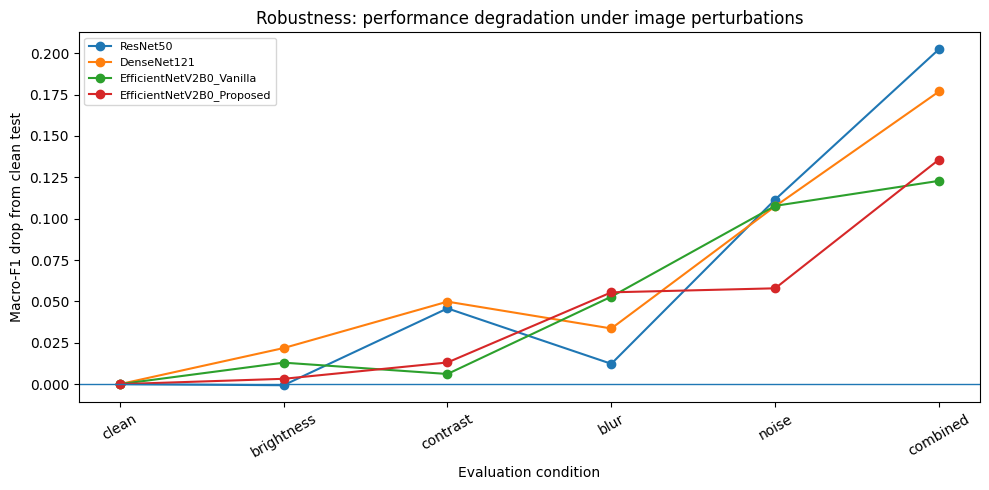

Lower mean Macro-F1 drop = more robust.


,mean_macro_F1_drop
model,
EfficientNetV2B0_Proposed,0.0531
EfficientNetV2B0_Vanilla,0.0605
ResNet50,0.0743
DenseNet121,0.0779


In [29]:
# Robustness evaluation: perturb the untouched test images only after model training/selection.
# No test result is used to tune weights, temperature, thresholds, or the final model.

ROBUSTNESS_MODELS = [
    k for k in [
        "ResNet50",
        "DenseNet121",
        "EfficientNetV2B0_Vanilla",
        "EfficientNetV2B0_Proposed",
    ] if k in trained_models
]

x_test = np.concatenate([x.numpy() for x, _ in test_ds], axis=0).astype("float32")
y_test = np.asarray(test_y, dtype="int64")
assert len(x_test) == len(y_test) == len(test_p)

def perturb_batch(x, kind, seed=SEED):
    t = tf.convert_to_tensor(x, dtype=tf.float32)
    if kind == "clean":
        return t
    if kind == "brightness":
        return tf.clip_by_value(t + 30.0, 0.0, 255.0)
    if kind == "contrast":
        return tf.clip_by_value(tf.image.adjust_contrast(t, 0.65), 0.0, 255.0)
    if kind == "blur":
        # Downsample then upsample: deterministic, inexpensive blur-like degradation.
        small = tf.image.resize(t, (112, 112), method="area")
        return tf.image.resize(small, IMG_SIZE, method="bilinear")
    if kind == "noise":
        g = tf.random.Generator.from_seed(seed)
        noise = g.normal(tf.shape(t), mean=0.0, stddev=18.0, dtype=tf.float32)
        return tf.clip_by_value(t + noise, 0.0, 255.0)
    if kind == "combined":
        z = tf.clip_by_value(t + 25.0, 0.0, 255.0)
        z = tf.image.adjust_contrast(z, 0.70)
        small = tf.image.resize(z, (112, 112), method="area")
        z = tf.image.resize(small, IMG_SIZE, method="bilinear")
        g = tf.random.Generator.from_seed(seed)
        z = z + g.normal(tf.shape(z), stddev=12.0, dtype=tf.float32)
        return tf.clip_by_value(z, 0.0, 255.0)
    raise ValueError(f"Unknown perturbation: {kind}")

PERTURBATIONS = ["clean", "brightness", "contrast", "blur", "noise", "combined"]

def evaluate_arrays(model, x, y):
    probs = model.predict(x, batch_size=BATCH_SIZE, verbose=0)
    pred = probs.argmax(axis=1)
    return {
        "accuracy": accuracy_score(y, pred),
        "macro_F1": f1_score(y, pred, average="macro", zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y, pred),
    }

robust_rows = []
for model_key in ROBUSTNESS_MODELS:
    model = trained_models[model_key]
    clean = evaluate_arrays(model, x_test, y_test)
    for perturbation in PERTURBATIONS:
        xp = perturb_batch(x_test, perturbation).numpy()
        met = evaluate_arrays(model, xp, y_test)
        robust_rows.append({
            "model": model_key,
            "condition": perturbation,
            **met,
            "macro_F1_drop_vs_clean": clean["macro_F1"] - met["macro_F1"],
        })

robustness_df = pd.DataFrame(robust_rows)
robustness_df.to_csv(f"{OUTPUT_DIR}/robustness_results.csv", index=False)

display(
    robustness_df.pivot(index="model", columns="condition", values="macro_F1")
    .round(4)
)

fig, ax = plt.subplots(figsize=(10, 5))
for model_key in ROBUSTNESS_MODELS:
    sub = robustness_df[robustness_df["model"] == model_key]
    ax.plot(sub["condition"], sub["macro_F1_drop_vs_clean"], marker="o", label=model_key)
ax.axhline(0, linewidth=1)
ax.set_ylabel("Macro-F1 drop from clean test")
ax.set_xlabel("Evaluation condition")
ax.set_title("Robustness: performance degradation under image perturbations")
ax.legend(fontsize=8)
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/robustness_f1_drop.png", dpi=200)
plt.show()

robust_summary = (
    robustness_df[robustness_df["condition"] != "clean"]
    .groupby("model")["macro_F1_drop_vs_clean"]
    .mean()
    .sort_values()
    .rename("mean_macro_F1_drop")
    .to_frame()
)
print("Lower mean Macro-F1 drop = more robust.")
display(robust_summary.round(4))

## 17. Probability Calibration — Can We Trust the Confidence Scores?

A classifier can be accurate but over-confident. Temperature scaling is fitted on the **validation set only** and then frozen before evaluation on the test set.

We report:
- **ECE** (Expected Calibration Error)
- **Brier score**
- test accuracy / macro-F1 after calibration

,temperature,test_accuracy,test_macro_F1,ECE_uncalibrated,ECE_calibrated,Brier_uncalibrated,Brier_calibrated
model,,,,,,,
ResNet50,1.45,0.7761,0.7727,0.0850,0.0430,0.3352,0.3232
DenseNet121,1.20,0.5957,0.5885,0.0697,0.0316,0.5523,0.5472
EfficientNetV2B0_Vanilla,0.80,0.6457,0.6529,0.0798,0.0597,0.4947,0.4872
EfficientNetV2B0_Proposed,0.60,0.6370,0.6508,0.1541,0.0501,0.5153,0.4790


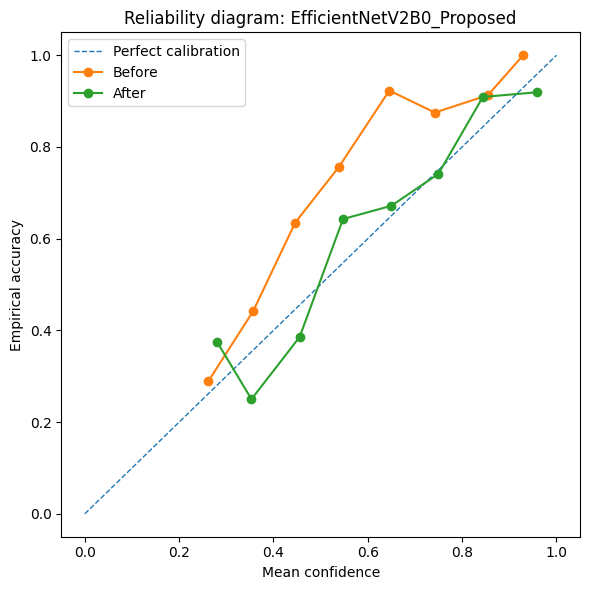

In [30]:
# Calibration is fitted on validation predictions only.
CALIBRATION_MODELS = ROBUSTNESS_MODELS

def collect_probs(model, ds):
    ys, ps = [], []
    for xb, yb in ds:
        ps.append(model.predict(xb, verbose=0))
        ys.append(yb.numpy())
    return np.concatenate(ys), np.concatenate(ps)

def probs_to_logits(probs):
    p = np.clip(probs, 1e-7, 1.0)
    z = np.log(p)
    return z - z.max(axis=1, keepdims=True)

def softmax_temp(logits, T):
    z = logits / float(T)
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def multiclass_nll(y, probs):
    p = np.clip(probs[np.arange(len(y)), y], 1e-7, 1.0)
    return float(-np.mean(np.log(p)))

def fit_temperature(y, probs):
    logits = probs_to_logits(probs)
    grid = np.linspace(0.5, 5.0, 91)
    losses = [multiclass_nll(y, softmax_temp(logits, T)) for T in grid]
    return float(grid[int(np.argmin(losses))])

def expected_calibration_error(y, probs, n_bins=15):
    conf = probs.max(axis=1)
    pred = probs.argmax(axis=1)
    ece = 0.0
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (conf > lo) & (conf <= hi)
        if np.any(mask):
            ece += mask.mean() * abs((pred[mask] == y[mask]).mean() - conf[mask].mean())
    return float(ece)

def multiclass_brier(y, probs):
    oh = np.eye(probs.shape[1], dtype=np.float32)[y]
    return float(np.mean(np.sum((probs - oh) ** 2, axis=1)))

calibration_rows = []
calibrated_test_probs = {}

for model_key in CALIBRATION_MODELS:
    model = trained_models[model_key]
    yv, pv = collect_probs(model, val_ds)
    yt, pt = collect_probs(model, test_ds)

    T = fit_temperature(yv, pv)
    pvt = softmax_temp(probs_to_logits(pv), T)
    ptt = softmax_temp(probs_to_logits(pt), T)

    calibrated_test_probs[model_key] = ptt
    calibration_rows.append({
        "model": model_key,
        "temperature": T,
        "test_accuracy": accuracy_score(yt, ptt.argmax(1)),
        "test_macro_F1": f1_score(yt, ptt.argmax(1), average="macro", zero_division=0),
        "ECE_uncalibrated": expected_calibration_error(yt, pt),
        "ECE_calibrated": expected_calibration_error(yt, ptt),
        "Brier_uncalibrated": multiclass_brier(yt, pt),
        "Brier_calibrated": multiclass_brier(yt, ptt),
    })

calibration_df = pd.DataFrame(calibration_rows).set_index("model")
calibration_df.to_csv(f"{OUTPUT_DIR}/calibration_results.csv")
display(calibration_df.round(4))

# Reliability diagram for the proposed model (or strongest available model).
best_model_key = results_df.index[0]
reliability_key = "EfficientNetV2B0_Proposed" if "EfficientNetV2B0_Proposed" in calibrated_test_probs else best_model_key

def reliability_points(y, probs, n_bins=10):
    conf = probs.max(axis=1)
    pred = probs.argmax(axis=1)
    bins = np.linspace(0, 1, n_bins + 1)
    out = []
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (conf > lo) & (conf <= hi)
        if np.any(mask):
            out.append(((lo + hi) / 2, conf[mask].mean(), (pred[mask] == y[mask]).mean(), mask.sum()))
    return pd.DataFrame(out, columns=["bin_center", "confidence", "accuracy", "count"])

yt_cal, pt_cal = collect_probs(trained_models[reliability_key], test_ds)
pt_calibrated = calibrated_test_probs[reliability_key]
rel_before = reliability_points(yt_cal, pt_cal)
rel_after = reliability_points(yt_cal, pt_calibrated)

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1, label="Perfect calibration")
ax.plot(rel_before["confidence"], rel_before["accuracy"], marker="o", label="Before")
ax.plot(rel_after["confidence"], rel_after["accuracy"], marker="o", label="After")
ax.set_xlabel("Mean confidence")
ax.set_ylabel("Empirical accuracy")
ax.set_title(f"Reliability diagram: {reliability_key}")
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/reliability_diagram.png", dpi=200)
plt.show()

## 18. Uncertainty & Selective Prediction — When Should the Model Ask for Human Review?

We use **predictive entropy** as an uncertainty score:

\[
H(p)=-\sum_c p_c\log p_c
\]

A useful deployment behavior is to **abstain on the most uncertain cases** instead of forcing a potentially unreliable disease label.

The abstention threshold is selected on the validation set, then frozen for the test set.

Validation threshold selected to target >= 90% retained accuracy.


,model,entropy_threshold,test_coverage,test_abstention_rate,test_accuracy_all,test_accuracy_retained,test_macro_F1_retained
0,EfficientNetV2B0_Proposed,0.3458,0.2174,0.7826,0.637,0.92,0.8709


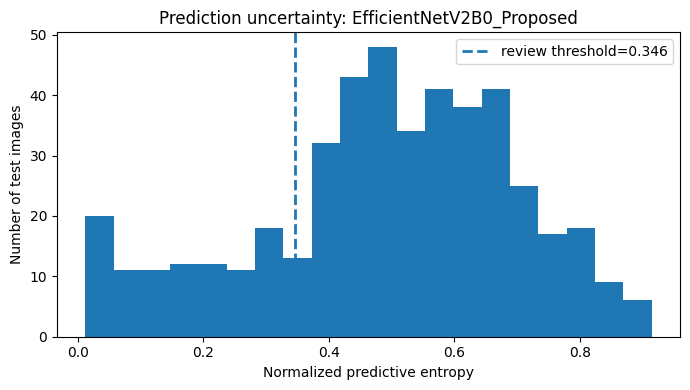

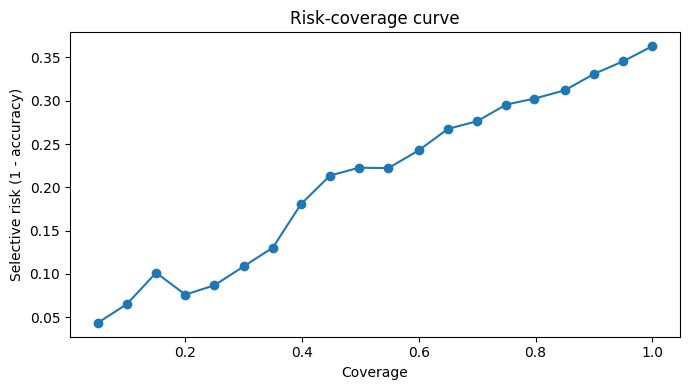

In [31]:
UNCERTAINTY_KEY = reliability_key

def predictive_entropy(probs):
    p = np.clip(probs, 1e-8, 1.0)
    return -np.sum(p * np.log(p), axis=1) / np.log(p.shape[1])

yv_u, pv_u = collect_probs(trained_models[UNCERTAINTY_KEY], val_ds)
yt_u, pt_u = collect_probs(trained_models[UNCERTAINTY_KEY], test_ds)

# Use calibrated validation probabilities when available.
pv_u = softmax_temp(probs_to_logits(pv_u), fit_temperature(yv_u, pv_u))
pt_u = calibrated_test_probs[UNCERTAINTY_KEY]

val_entropy = predictive_entropy(pv_u)
test_entropy = predictive_entropy(pt_u)

# Select the largest validation coverage whose retained accuracy reaches the target.
TARGET_SELECTIVE_ACCURACY = 0.90
candidate_thresholds = np.unique(np.quantile(val_entropy, np.linspace(0.0, 1.0, 101)))
chosen = None

for thr in np.sort(candidate_thresholds):
    keep_mask = val_entropy <= thr
    if keep_mask.sum() == 0:
        continue
    acc = accuracy_score(yv_u[keep_mask], pv_u[keep_mask].argmax(1))
    coverage = keep_mask.mean()
    if acc >= TARGET_SELECTIVE_ACCURACY:
        if chosen is None or coverage > chosen["coverage"]:
            chosen = {"threshold": float(thr), "coverage": float(coverage), "accuracy": float(acc)}

if chosen is None:
    # If 90% cannot be reached, choose the validation threshold with highest retained accuracy.
    candidates = []
    for thr in np.sort(candidate_thresholds):
        keep_mask = val_entropy <= thr
        if keep_mask.sum():
            candidates.append((accuracy_score(yv_u[keep_mask], pv_u[keep_mask].argmax(1)),
                               keep_mask.mean(), thr))
    best_acc, best_cov, best_thr = max(candidates, key=lambda z: (z[0], z[1]))
    chosen = {"threshold": float(best_thr), "coverage": float(best_cov), "accuracy": float(best_acc)}
    print("Validation could not reach the target selective accuracy; using the best validation accuracy threshold.")
else:
    print(f"Validation threshold selected to target >= {TARGET_SELECTIVE_ACCURACY:.0%} retained accuracy.")

thr = chosen["threshold"]
test_keep = test_entropy <= thr
test_pred = pt_u.argmax(1)

uncertainty_summary = pd.DataFrame([{
    "model": UNCERTAINTY_KEY,
    "entropy_threshold": thr,
    "test_coverage": test_keep.mean(),
    "test_abstention_rate": 1.0 - test_keep.mean(),
    "test_accuracy_all": accuracy_score(yt_u, test_pred),
    "test_accuracy_retained": accuracy_score(yt_u[test_keep], test_pred[test_keep]) if test_keep.any() else np.nan,
    "test_macro_F1_retained": f1_score(yt_u[test_keep], test_pred[test_keep], average="macro", zero_division=0) if test_keep.any() else np.nan,
}])

uncertainty_summary.to_csv(f"{OUTPUT_DIR}/uncertainty_selective_prediction.csv", index=False)
display(uncertainty_summary.round(4))

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(test_entropy, bins=20)
ax.axvline(thr, linestyle="--", linewidth=2, label=f"review threshold={thr:.3f}")
ax.set_xlabel("Normalized predictive entropy")
ax.set_ylabel("Number of test images")
ax.set_title(f"Prediction uncertainty: {UNCERTAINTY_KEY}")
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/uncertainty_histogram.png", dpi=200)
plt.show()

# Risk-coverage curve on the untouched test set (descriptive; no threshold tuning here).
order = np.argsort(test_entropy)
coverages, risks = [], []
for frac in np.linspace(0.05, 1.0, 20):
    n = max(1, int(frac * len(order)))
    keep = order[:n]
    coverages.append(n / len(order))
    risks.append(1.0 - accuracy_score(yt_u[keep], test_pred[keep]))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(coverages, risks, marker="o")
ax.set_xlabel("Coverage")
ax.set_ylabel("Selective risk (1 - accuracy)")
ax.set_title("Risk-coverage curve")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/risk_coverage_curve.png", dpi=200)
plt.show()

## 19. Explainability Robustness — Is the Model Looking at Stable Leaf Regions?

Grad-CAM is retained, but the analysis is upgraded from a few visual examples to a **stability analysis**.

For correctly classified test images, we compare Grad-CAM maps for:
- the original image
- brightness-degraded image
- blurred image

This measures **explanation stability**, not biological localization accuracy, because no lesion segmentation masks are available.

,cam_cosine_similarity,cam_top20_iou,prediction_preserved
condition,,,
blur,0.5000,0.1851,0.8667
brightness,0.5814,0.2605,0.9000


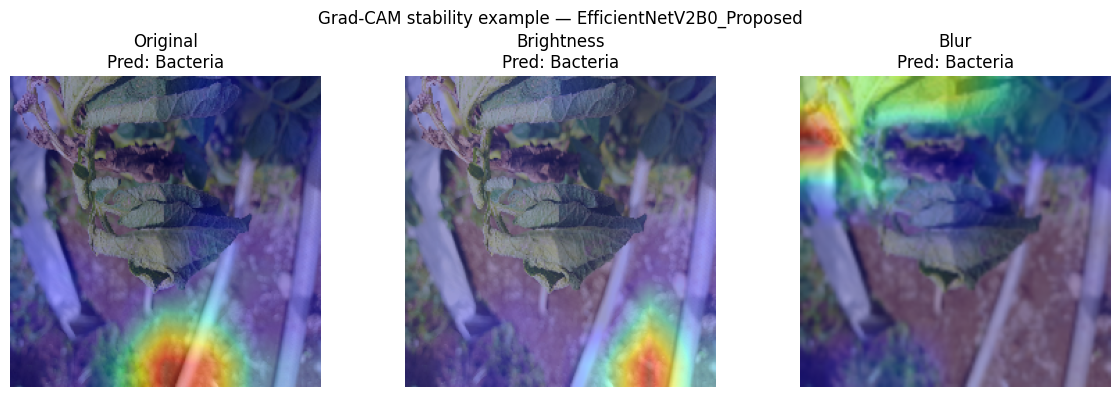

In [32]:
# Quantitative Grad-CAM stability for the proposed/selected model.
XAI_KEY = "EfficientNetV2B0_Proposed" if "EfficientNetV2B0_Proposed" in trained_models else best_model_key
XAI_MODEL = trained_models[XAI_KEY]
XAI_LAYER = find_last_conv_layer(XAI_MODEL)

xai_probs = XAI_MODEL.predict(x_test, batch_size=BATCH_SIZE, verbose=0)
xai_pred = xai_probs.argmax(1)
correct_idx = np.where(xai_pred == y_test)[0]

# Limit the visualization/analysis to a deterministic subset for computational efficiency.
N_XAI = min(30, len(correct_idx))
xai_indices = correct_idx[:N_XAI]

def normalized_flat(hm):
    v = np.asarray(hm, dtype="float32")
    v = np.maximum(v, 0)
    v = v / (v.max() + 1e-8)
    return v.ravel()

def cosine_similarity(a, b):
    denom = np.linalg.norm(a) * np.linalg.norm(b)
    return float(np.dot(a, b) / denom) if denom > 0 else np.nan

def top_fraction_iou(a, b, frac=0.20):
    aa = np.asarray(a).ravel()
    bb = np.asarray(b).ravel()
    ka = max(1, int(frac * len(aa)))
    ia = set(np.argpartition(aa, -ka)[-ka:])
    ib = set(np.argpartition(bb, -ka)[-ka:])
    return len(ia & ib) / max(len(ia | ib), 1)

stability_rows = []
for idx in xai_indices:
    original = x_test[idx]
    variants = {
        "brightness": perturb_batch(original[None], "brightness").numpy()[0],
        "blur": perturb_batch(original[None], "blur").numpy()[0],
    }

    hm_orig, pred_orig = make_gradcam_heatmap(
        original[None], XAI_MODEL, XAI_LAYER
    )
    base = normalized_flat(hm_orig)

    for condition, img_var in variants.items():
        hm_var, pred_var = make_gradcam_heatmap(
            img_var[None], XAI_MODEL, XAI_LAYER
        )
        var = normalized_flat(hm_var)
        stability_rows.append({
            "index": int(idx),
            "true_class": class_names[int(y_test[idx])],
            "condition": condition,
            "original_prediction": class_names[int(pred_orig)],
            "perturbed_prediction": class_names[int(pred_var)],
            "prediction_preserved": bool(pred_orig == pred_var),
            "cam_cosine_similarity": cosine_similarity(base, var),
            "cam_top20_iou": top_fraction_iou(base, var, frac=0.20),
        })

xai_stability_df = pd.DataFrame(stability_rows)
xai_stability_df.to_csv(f"{OUTPUT_DIR}/gradcam_stability.csv", index=False)

display(
    xai_stability_df.groupby("condition")[
        ["cam_cosine_similarity", "cam_top20_iou", "prediction_preserved"]
    ].agg({
        "cam_cosine_similarity": "mean",
        "cam_top20_iou": "mean",
        "prediction_preserved": "mean",
    }).round(4)
)

# Representative visual comparison.
if len(xai_indices):
    idx = int(xai_indices[0])
    imgs = [
        ("Original", x_test[idx]),
        ("Brightness", perturb_batch(x_test[idx][None], "brightness").numpy()[0]),
        ("Blur", perturb_batch(x_test[idx][None], "blur").numpy()[0]),
    ]
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    for ax, (title, imgv) in zip(axes, imgs):
        hm, pred = make_gradcam_heatmap(imgv[None], XAI_MODEL, XAI_LAYER)
        ax.imshow(overlay_gradcam(imgv, hm))
        ax.set_title(f"{title}\nPred: {class_names[pred]}")
        ax.axis("off")
    plt.suptitle(f"Grad-CAM stability example — {XAI_KEY}")
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/gradcam_stability_example.png", dpi=200)
    plt.show()

## 20. Final Model Selection, Reproducibility & Inference

The final model is selected **only by validation macro-F1**. The test set is not used for model selection.

The saved package includes the model, class names, calibration temperature, and the key experimental settings.

In [33]:
# Final selection is validation-only.
best_model_key = results_df.index[0]
best_model = trained_models[best_model_key]

best_model.save(f"{OUTPUT_DIR}/best_model_{best_model_key}.keras")
with open(f"{OUTPUT_DIR}/class_names.json", "w") as f:
    json.dump(class_names, f)

final_metadata = {
    "selected_model": best_model_key,
    "selection_metric": "validation macro-F1",
    "test_set_used_for_selection": False,
    "class_names": list(class_names),
    "img_size": list(IMG_SIZE),
    "seed": SEED,
    "robustness_perturbations": PERTURBATIONS,
    "calibration_temperature": float(calibration_df.loc[best_model_key, "temperature"])
        if best_model_key in calibration_df.index else None,
    "uncertainty_method": "normalized predictive entropy",
    "xai_method": "Grad-CAM",
}
with open(f"{OUTPUT_DIR}/final_metadata.json", "w") as f:
    json.dump(final_metadata, f, indent=2)

results_df.to_csv(f"{OUTPUT_DIR}/final_model_comparison.csv")
print("Final model:", best_model_key)
print("Saved:", f"{OUTPUT_DIR}/best_model_{best_model_key}.keras")
print("Selection rule: validation macro-F1 only.")
print(json.dumps(final_metadata, indent=2))

Final model: ResNet50
Saved: results/best_model_ResNet50.keras
Selection rule: validation macro-F1 only.
{
  "selected_model": "ResNet50",
  "selection_metric": "validation macro-F1",
  "test_set_used_for_selection": false,
  "class_names": [
    "Bacteria",
    "Fungi",
    "Healthy",
    "Nematode",
    "Pest",
    "Phytopthora",
    "Virus"
  ],
  "img_size": [
    224,
    224
  ],
  "seed": 42,
  "robustness_perturbations": [
    "clean",
    "brightness",
    "contrast",
    "blur",
    "noise",
    "combined"
  ],
  "calibration_temperature": 1.4500000000000002,
  "uncertainty_method": "normalized predictive entropy",
  "xai_method": "Grad-CAM"
}


## 21. Quick Inference Test

In [34]:
def predict_image(model, image_path, class_names, img_size=IMG_SIZE):
    img = tf.keras.utils.load_img(image_path, target_size=img_size)
    img_array = tf.keras.utils.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    probs = model.predict(img_array, verbose=0)[0]
    pred_idx = np.argmax(probs)
    return class_names[pred_idx], probs[pred_idx]


first_class_dir = os.listdir(dataset_path)[0]
first_class_path = os.path.join(dataset_path, first_class_dir)
sample_image_filename = os.listdir(first_class_path)[0]
sample_image_path = os.path.join(first_class_path, sample_image_filename)

label, confidence = predict_image(best_model, sample_image_path, class_names)
print(f"Predicted class for {sample_image_filename}: {label} (confidence: {confidence:.3f})")

Predicted class for 20230802_105249.jpg: Nematode (confidence: 1.000)


## 22. Comparative Experiment — Pretrained Vision Transformer (ViT) + Fine-Tuning

**Purpose:** compare the existing CNN baseline(s) with a pretrained Vision Transformer using the same verified train/validation/test file lists. Fine-tuning is a training strategy; ViT is an architecture, so this experiment uses both.

**Design:** `google/vit-base-patch16-224-in21k`; train the classification head for 5 epochs, then fine-tune the final four Transformer blocks plus final layer norm for 25 epochs. The best checkpoint is selected by **validation Macro-F1 only**. The test set is used once for final reporting, not for checkpoint selection.

**Important:** this experiment uses PyTorch + Hugging Face Transformers alongside the TensorFlow CNN experiments above. Run in a GPU runtime if available. This section is intentionally separate because CNN-specific Grad-CAM functions do not directly apply to ViT. ViT attribution should use a Transformer-compatible method in a separate analysis.

The same train/validation/test split arrays (`train_p`, `train_y`, `val_p`, `val_y`, `test_p`, `test_y`) created above are reused. If the duplicate-aware split was rebuilt, that rebuilt split is used here too.


In [35]:
# ViT experiment settings. Set RUN_VIT_EXPERIMENT=False to skip this optional, compute-intensive section.
RUN_VIT_EXPERIMENT = True
VIT_CHECKPOINT = "google/vit-base-patch16-224-in21k"
VIT_PHASE1_EPOCHS = 5
VIT_PHASE2_EPOCHS = 25
VIT_UNFREEZE_LAST_N = 4  # ViT tweak: previously only 2 final transformer encoder blocks were trainable.
assert VIT_PHASE1_EPOCHS + VIT_PHASE2_EPOCHS == 30
VIT_BATCH_SIZE = 16  # ViT-base is larger than ResNet50; lower to 8 if GPU memory is limited.
VIT_NUM_WORKERS = 2
VIT_OUTPUT_DIR = os.path.join(OUTPUT_DIR, "vit")
os.makedirs(VIT_OUTPUT_DIR, exist_ok=True)

if RUN_VIT_EXPERIMENT:
    import copy, time, random
    import torch
    from torch import nn
    from torch.utils.data import Dataset, DataLoader
    from torchvision import transforms
    from PIL import Image
    from transformers import ViTImageProcessor, ViTForImageClassification
    from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score, roc_auc_score

    # Reproducibility across Python, NumPy and PyTorch.
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("ViT device:", device)
    if device.type == "cpu":
        print("WARNING: ViT-base fine-tuning can be slow on CPU. A GPU runtime is recommended.")

    vit_processor = ViTImageProcessor.from_pretrained(VIT_CHECKPOINT)
    vit_mean = vit_processor.image_mean
    vit_std = vit_processor.image_std
    vit_train_transform = transforms.Compose([
        transforms.Resize((IMG_SIZE[0], IMG_SIZE[1])),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomVerticalFlip(p=0.5),
        transforms.RandomRotation(10),
        transforms.ColorJitter(brightness=0.10, contrast=0.10),
        transforms.ToTensor(),
        transforms.Normalize(mean=vit_mean, std=vit_std),
    ])
    vit_eval_transform = transforms.Compose([
        transforms.Resize((IMG_SIZE[0], IMG_SIZE[1])),
        transforms.ToTensor(),
        transforms.Normalize(mean=vit_mean, std=vit_std),
    ])

    class PotatoLeafTorchDataset(Dataset):
        def __init__(self, paths, labels, transform):
            self.paths = list(paths)
            self.labels = np.asarray(labels, dtype=np.int64)
            self.transform = transform
        def __len__(self):
            return len(self.paths)
        def __getitem__(self, idx):
            with Image.open(self.paths[idx]) as im:
                image = im.convert("RGB")
            return self.transform(image), int(self.labels[idx])

    vit_train_loader = DataLoader(PotatoLeafTorchDataset(train_p, train_y, vit_train_transform),
                                  batch_size=VIT_BATCH_SIZE, shuffle=True, num_workers=VIT_NUM_WORKERS,
                                  pin_memory=(device.type == "cuda"))
    vit_val_loader = DataLoader(PotatoLeafTorchDataset(val_p, val_y, vit_eval_transform),
                                batch_size=VIT_BATCH_SIZE, shuffle=False, num_workers=VIT_NUM_WORKERS,
                                pin_memory=(device.type == "cuda"))
    vit_test_loader = DataLoader(PotatoLeafTorchDataset(test_p, test_y, vit_eval_transform),
                                 batch_size=VIT_BATCH_SIZE, shuffle=False, num_workers=VIT_NUM_WORKERS,
                                 pin_memory=(device.type == "cuda"))

    vit_id2label = {i: name for i, name in enumerate(class_names)}
    vit_label2id = {name: i for i, name in enumerate(class_names)}
    vit_model = ViTForImageClassification.from_pretrained(
        VIT_CHECKPOINT,
        num_labels=NUM_CLASSES,
        id2label=vit_id2label,
        label2id=vit_label2id,
        ignore_mismatched_sizes=True,
    ).to(device)

    def vit_run_epoch(model, loader, optimizer=None):
        training = optimizer is not None
        model.train(training)
        loss_sum, n_seen, all_y, all_probs = 0.0, 0, [], []
        for pixel_values, labels in loader:
            pixel_values = pixel_values.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            if training:
                optimizer.zero_grad(set_to_none=True)
            with torch.set_grad_enabled(training):
                out = model(pixel_values=pixel_values, labels=labels)
                loss = out.loss
                if training:
                    loss.backward()
                    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                    optimizer.step()
            probs = torch.softmax(out.logits.detach(), dim=1).cpu().numpy()
            all_probs.append(probs)
            all_y.append(labels.detach().cpu().numpy())
            batch_n = len(labels)
            loss_sum += float(loss.detach().cpu()) * batch_n
            n_seen += batch_n
        y = np.concatenate(all_y)
        probs = np.concatenate(all_probs)
        return loss_sum / max(n_seen, 1), y, probs

    vit_best_f1 = -1.0
    vit_best_epoch = None
    vit_history = []
    vit_t0 = time.time()

    # Phase 1: freeze the entire encoder; train only the new seven-class head.
    for p in vit_model.vit.parameters():
        p.requires_grad = False
    for p in vit_model.classifier.parameters():
        p.requires_grad = True
    optimizer = torch.optim.AdamW((p for p in vit_model.parameters() if p.requires_grad), lr=2e-4, weight_decay=0.01)
    for epoch in range(VIT_PHASE1_EPOCHS):
        train_loss, _, _ = vit_run_epoch(vit_model, vit_train_loader, optimizer)
        val_loss, vy, vp = vit_run_epoch(vit_model, vit_val_loader)
        val_f1 = f1_score(vy, vp.argmax(1), average="macro", zero_division=0)
        row = {"epoch": epoch + 1, "stage": "head_only", "train_loss": train_loss, "val_loss": val_loss, "val_macro_f1": val_f1}
        vit_history.append(row)
        print(f"ViT epoch {epoch+1:02d}/{VIT_PHASE1_EPOCHS+VIT_PHASE2_EPOCHS} [head] train_loss={train_loss:.4f} val_loss={val_loss:.4f} val_macro_F1={val_f1:.4f}")
        if val_f1 > vit_best_f1:
            vit_best_f1, vit_best_epoch = val_f1, epoch + 1
            torch.save(vit_model.state_dict(), os.path.join(VIT_OUTPUT_DIR, "best_model_state.pt"))

    # Phase 2: fine-tune the final four Transformer encoder blocks and final layer norm.
    for p in vit_model.vit.parameters():
        p.requires_grad = False
    for layer in vit_model.vit.encoder.layer[-VIT_UNFREEZE_LAST_N:]:
        for p in layer.parameters():
            p.requires_grad = True
    for p in vit_model.vit.layernorm.parameters():
        p.requires_grad = True
    for p in vit_model.classifier.parameters():
        p.requires_grad = True
    backbone_params = [p for n, p in vit_model.named_parameters() if p.requires_grad and not n.startswith("classifier.")]
    head_params = list(vit_model.classifier.parameters())
    optimizer = torch.optim.AdamW([
        {"params": backbone_params, "lr": 2e-5},
        {"params": head_params, "lr": 2e-4},
    ], weight_decay=0.01)

    for epoch in range(VIT_PHASE2_EPOCHS):
        global_epoch = VIT_PHASE1_EPOCHS + epoch + 1
        train_loss, _, _ = vit_run_epoch(vit_model, vit_train_loader, optimizer)
        val_loss, vy, vp = vit_run_epoch(vit_model, vit_val_loader)
        val_f1 = f1_score(vy, vp.argmax(1), average="macro", zero_division=0)
        row = {"epoch": global_epoch, "stage": "partial_finetune", "train_loss": train_loss, "val_loss": val_loss, "val_macro_f1": val_f1}
        vit_history.append(row)
        print(f"ViT epoch {global_epoch:02d}/{VIT_PHASE1_EPOCHS+VIT_PHASE2_EPOCHS} [fine-tune] train_loss={train_loss:.4f} val_loss={val_loss:.4f} val_macro_F1={val_f1:.4f}")
        if val_f1 > vit_best_f1:
            vit_best_f1, vit_best_epoch = val_f1, global_epoch
            torch.save(vit_model.state_dict(), os.path.join(VIT_OUTPUT_DIR, "best_model_state.pt"))

    assert len(vit_history) == VIT_PHASE1_EPOCHS + VIT_PHASE2_EPOCHS, f"ViT completed {len(vit_history)} / {VIT_PHASE1_EPOCHS + VIT_PHASE2_EPOCHS} epochs"
    vit_train_time_s = time.time() - vit_t0
    vit_model.load_state_dict(torch.load(os.path.join(VIT_OUTPUT_DIR, "best_model_state.pt"), map_location=device))
    vit_model.eval()
    pd.DataFrame(vit_history).to_csv(os.path.join(VIT_OUTPUT_DIR, "training_history.csv"), index=False)
    vit_model.save_pretrained(os.path.join(VIT_OUTPUT_DIR, "best_model"))
    vit_processor.save_pretrained(os.path.join(VIT_OUTPUT_DIR, "best_model"))

    def vit_predict_loader(model, loader):
        model.eval()
        ys, ps = [], []
        with torch.no_grad():
            for pixel_values, labels in loader:
                out = model(pixel_values=pixel_values.to(device, non_blocking=True))
                ps.append(torch.softmax(out.logits, dim=1).cpu().numpy())
                ys.append(labels.numpy())
        return np.concatenate(ys), np.concatenate(ps)

    vit_y_val, vit_p_val = vit_predict_loader(vit_model, vit_val_loader)
    vit_y_test, vit_p_test = vit_predict_loader(vit_model, vit_test_loader)

    def vit_metrics(y, probs):
        pred = probs.argmax(axis=1)
        y_oh = np.eye(NUM_CLASSES)[y]
        return {
            "accuracy": accuracy_score(y, pred),
            "precision_macro": precision_score(y, pred, average="macro", zero_division=0),
            "recall_macro": recall_score(y, pred, average="macro", zero_division=0),
            "f1_macro": f1_score(y, pred, average="macro", zero_division=0),
            "f1_weighted": f1_score(y, pred, average="weighted", zero_division=0),
            "balanced_accuracy": balanced_accuracy_score(y, pred),
            "roc_auc_macro": roc_auc_score(y_oh, probs, average="macro", multi_class="ovr"),
        }

    vit_val_metrics = vit_metrics(vit_y_val, vit_p_val)
    vit_test_metrics = vit_metrics(vit_y_test, vit_p_test)
    vit_test_metrics["val_f1_macro"] = vit_val_metrics["f1_macro"]
    vit_test_metrics["epochs"] = len(vit_history)
    vit_test_metrics["train_time_min"] = vit_train_time_s / 60.0
    vit_test_metrics["best_epoch"] = vit_best_epoch
    vit_test_metrics["model_type"] = "ViT (PyTorch/Hugging Face)"

    # Save the ViT-only result and an aligned comparison table with the existing CNN results.
    pd.DataFrame([{"split": "validation", **vit_val_metrics}, {"split": "test", **vit_test_metrics}]).to_csv(
        os.path.join(VIT_OUTPUT_DIR, "vit_metrics.csv"), index=False)
    comparison_all = results_df.copy()
    for col in comparison_all.columns:
        if col not in vit_test_metrics:
            vit_test_metrics[col] = np.nan
    for col in vit_test_metrics:
        if col not in comparison_all.columns:
            comparison_all[col] = np.nan
    comparison_all.loc["ViT_Base_PartialFineTune"] = pd.Series(vit_test_metrics)
    comparison_all = comparison_all.sort_values("val_f1_macro", ascending=False)
    comparison_all.to_csv(os.path.join(OUTPUT_DIR, "model_comparison_with_vit.csv"))
    display(comparison_all.round(4))

    print(f"ViT best validation Macro-F1: {vit_best_f1:.4f} at epoch {vit_best_epoch}")
    print("ViT test metrics:", {k: round(v, 4) for k, v in vit_test_metrics.items() if isinstance(v, (int, float, np.integer, np.floating)) and pd.notna(v)})
    print("Saved ViT checkpoint folder:", os.path.join(VIT_OUTPUT_DIR, "best_model"))


ViT device: cuda


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Some weights of ViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224-in21k and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


ViT epoch 01/30 [head] train_loss=1.6766 val_loss=1.5235 val_macro_F1=0.2966
ViT epoch 02/30 [head] train_loss=1.3906 val_loss=1.3431 val_macro_F1=0.3511
ViT epoch 03/30 [head] train_loss=1.2322 val_loss=1.2229 val_macro_F1=0.4079
ViT epoch 04/30 [head] train_loss=1.1280 val_loss=1.1407 val_macro_F1=0.5069
ViT epoch 05/30 [head] train_loss=1.0532 val_loss=1.0792 val_macro_F1=0.5514
ViT epoch 06/30 [fine-tune] train_loss=0.7939 val_loss=0.7101 val_macro_F1=0.6640
ViT epoch 07/30 [fine-tune] train_loss=0.5731 val_loss=0.5618 val_macro_F1=0.7536
ViT epoch 08/30 [fine-tune] train_loss=0.4217 val_loss=0.4866 val_macro_F1=0.8003
ViT epoch 09/30 [fine-tune] train_loss=0.3431 val_loss=0.4573 val_macro_F1=0.8203
ViT epoch 10/30 [fine-tune] train_loss=0.2796 val_loss=0.4179 val_macro_F1=0.8312
ViT epoch 11/30 [fine-tune] train_loss=0.2317 val_loss=0.4241 val_macro_F1=0.8321
ViT epoch 12/30 [fine-tune] train_loss=0.1906 val_loss=0.3990 val_macro_F1=0.8441
ViT epoch 13/30 [fine-tune] train_loss=0.

,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,balanced_accuracy,roc_auc_macro,val_f1_macro,epochs,train_time_min,best_epoch,model_type
ViT_Base_PartialFineTune,0.8478,0.8280,0.8192,0.8228,0.8467,0.8192,0.9815,0.8674,30,34.3703,23.0,ViT (PyTorch/Hugging Face)
ResNet50,0.7761,0.7660,0.8044,0.7730,0.7783,0.8044,0.9617,0.7727,50,13.0551,NaN,NaN
EfficientNetV2B0_SE,0.7000,0.7123,0.7336,0.7055,0.7070,0.7336,0.9412,0.7229,50,6.2786,NaN,NaN
EfficientNetV2B0_Focal,0.6913,0.6895,0.7148,0.6860,0.7026,0.7148,0.9340,0.7026,50,6.4606,NaN,NaN
EfficientNetV2B0_Vanilla,0.6457,0.6717,0.7021,0.6529,0.6539,0.7021,0.9230,0.6655,50,6.1658,NaN,NaN
EfficientNetV2B0_Proposed,0.6370,0.6739,0.6683,0.6508,0.6479,0.6683,0.9259,0.6564,50,6.3254,NaN,NaN
EfficientNetV2B0_PlainCE,0.6978,0.7031,0.6959,0.6810,0.7081,0.6959,0.9422,0.6274,50,6.3842,NaN,NaN
DenseNet121,0.5957,0.6088,0.6902,0.5885,0.6059,0.6902,0.9139,0.5950,50,12.0497,NaN,NaN


ViT best validation Macro-F1: 0.8674 at epoch 23
ViT test metrics: {'accuracy': 0.8478, 'precision_macro': 0.828, 'recall_macro': 0.8192, 'f1_macro': 0.8228, 'f1_weighted': 0.8467, 'balanced_accuracy': np.float64(0.8192), 'roc_auc_macro': np.float64(0.9815), 'val_f1_macro': 0.8674, 'epochs': 30, 'train_time_min': 34.3703, 'best_epoch': 23}
Saved ViT checkpoint folder: results/vit/best_model


## 22.1 [ADDED] Top-2 and Top-3 Soft-Voting Ensembles

This section adds the missing ensemble experiments. Each member is selected by **validation macro-F1 only**. The selected top-2 and top-3 models are combined by averaging their class-probability vectors (soft voting), then evaluated on the held-out test set. The test set is not used to select members or tune the ensemble.

The optional ViT is included as a candidate when `RUN_VIT_EXPERIMENT=True`; CNN and ViT probabilities use the same `class_names` ordering and deterministic validation/test split. If ViT is disabled, the ensemble candidates are the CNN models only.


,model,framework,val_f1_macro
0,ViT_Base_PartialFineTune,PyTorch/Hugging Face,0.867377
1,ResNet50,TensorFlow/Keras,0.771464
2,EfficientNetV2B0_SE,TensorFlow/Keras,0.722857
3,EfficientNetV2B0_Focal,TensorFlow/Keras,0.702634
4,EfficientNetV2B0_Vanilla,TensorFlow/Keras,0.665494
5,EfficientNetV2B0_Proposed,TensorFlow/Keras,0.656421
6,EfficientNetV2B0_PlainCE,TensorFlow/Keras,0.627382
7,DenseNet121,TensorFlow/Keras,0.595010


Top-2 ensemble members (validation macro-F1): ['ViT_Base_PartialFineTune', 'ResNet50']
Top-3 ensemble members (validation macro-F1): ['ViT_Base_PartialFineTune', 'ResNet50', 'EfficientNetV2B0_SE']


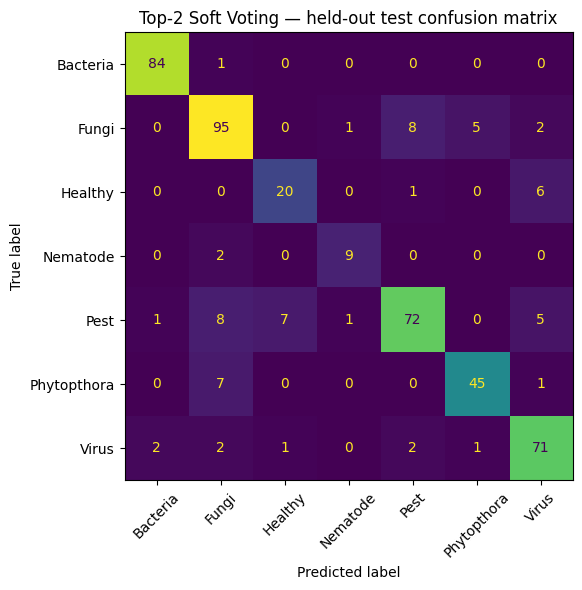

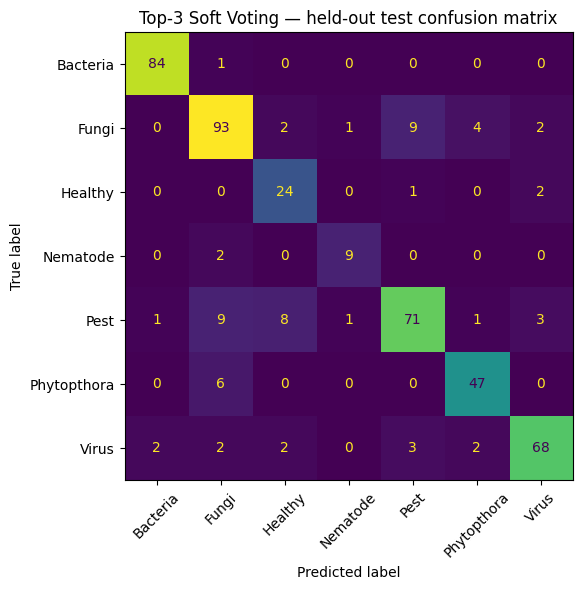

,experiment,members,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,balanced_accuracy,roc_auc_macro,val_f1_macro
0,Top-2 Soft Voting,ViT_Base_PartialFineTune + ResNet50,0.8609,0.8442,0.8453,0.8440,0.8603,0.8453,0.9821,0.8857
1,Top-3 Soft Voting,ViT_Base_PartialFineTune + ResNet50 + Efficien...,0.8609,0.8422,0.8623,0.8495,0.8610,0.8623,0.9786,0.8890


Saved combined individual-model + ensemble comparison: results/model_and_ensemble_comparison.csv
Saved ensemble results to: results


In [36]:
# ADDED: Top-2 and Top-3 soft-voting ensembles, selected using validation macro-F1.
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_auc_score
)

# Validate that labels and prediction rows use the same deterministic split order.
assert len(val_y) == len(val_ds.file_paths) if hasattr(val_ds, "file_paths") else True
assert len(test_y) == len(test_p), "Test labels and test paths have different lengths."

ensemble_candidates = {}

# CNN candidates: use the existing trained_models and predict on validation/test datasets.
for model_key, model in trained_models.items():
    val_prob = model.predict(val_ds, verbose=0)
    test_prob = model.predict(test_ds, verbose=0)
    if len(val_prob) != len(val_y) or len(test_prob) != len(test_y):
        raise ValueError(f"Prediction count mismatch for {model_key}.")
    val_macro_f1 = f1_score(val_y, np.argmax(val_prob, axis=1), average="macro", zero_division=0)
    ensemble_candidates[model_key] = {
        "framework": "TensorFlow/Keras",
        "val_macro_f1": float(val_macro_f1),
        "val_probabilities": val_prob,
        "test_probabilities": test_prob,
    }

# Optional ViT candidate: these probabilities were generated in the ViT section above.
if RUN_VIT_EXPERIMENT:
    if not np.array_equal(np.asarray(vit_y_val), np.asarray(val_y)):
        raise ValueError("ViT validation labels are not aligned with the CNN validation split.")
    if not np.array_equal(np.asarray(vit_y_test), np.asarray(test_y)):
        raise ValueError("ViT test labels are not aligned with the CNN test split.")
    ensemble_candidates["ViT_Base_PartialFineTune"] = {
        "framework": "PyTorch/Hugging Face",
        "val_macro_f1": float(f1_score(
            val_y, np.argmax(vit_p_val, axis=1), average="macro", zero_division=0
        )),
        "val_probabilities": np.asarray(vit_p_val),
        "test_probabilities": np.asarray(vit_p_test),
    }

if len(ensemble_candidates) < 3:
    raise RuntimeError(
        f"At least 3 trained candidates are needed for top-2 and top-3 ensembles; "
        f"found {len(ensemble_candidates)}."
    )

# Important: rank members using validation macro-F1 only, never test metrics.
ensemble_ranking = pd.DataFrame([
    {"model": key, "framework": value["framework"], "val_f1_macro": value["val_macro_f1"]}
    for key, value in ensemble_candidates.items()
]).sort_values("val_f1_macro", ascending=False).reset_index(drop=True)
ensemble_ranking.to_csv(os.path.join(OUTPUT_DIR, "ensemble_member_validation_ranking.csv"), index=False)
display(ensemble_ranking)

ranked_candidate_names = ensemble_ranking["model"].tolist()
top2_members = ranked_candidate_names[:2]
top3_members = ranked_candidate_names[:3]
print("Top-2 ensemble members (validation macro-F1):", top2_members)
print("Top-3 ensemble members (validation macro-F1):", top3_members)

# Average predicted probabilities (equal-weight soft voting).
ensemble_probabilities = {
    "Top-2 Soft Voting": np.mean(
        [ensemble_candidates[name]["test_probabilities"] for name in top2_members], axis=0
    ),
    "Top-3 Soft Voting": np.mean(
        [ensemble_candidates[name]["test_probabilities"] for name in top3_members], axis=0
    ),
}
ensemble_validation_probabilities = {
    "Top-2 Soft Voting": np.mean(
        [ensemble_candidates[name]["val_probabilities"] for name in top2_members], axis=0
    ),
    "Top-3 Soft Voting": np.mean(
        [ensemble_candidates[name]["val_probabilities"] for name in top3_members], axis=0
    ),
}

# Metrics are computed on the held-out test set for final reporting only.
def _ensemble_metrics(y_true, probs, name, members):
    pred = np.argmax(probs, axis=1)
    row = {
        "experiment": name,
        "members": " + ".join(members),
        "accuracy": float(accuracy_score(y_true, pred)),
        "precision_macro": float(precision_score(y_true, pred, average="macro", zero_division=0)),
        "recall_macro": float(recall_score(y_true, pred, average="macro", zero_division=0)),
        "f1_macro": float(f1_score(y_true, pred, average="macro", zero_division=0)),
        "f1_weighted": float(f1_score(y_true, pred, average="weighted", zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, pred)),
    }
    try:
        y_onehot = np.eye(NUM_CLASSES)[np.asarray(y_true, dtype=int)]
        row["roc_auc_macro"] = float(roc_auc_score(
            y_onehot, probs, average="macro", multi_class="ovr"
        ))
    except ValueError as exc:
        row["roc_auc_macro"] = np.nan
        print(f"ROC-AUC could not be calculated for {name}: {exc}")
    return row

ensemble_rows = []
for ensemble_name, probs in ensemble_probabilities.items():
    members = top2_members if ensemble_name.startswith("Top-2") else top3_members
    row = _ensemble_metrics(test_y, probs, ensemble_name, members)
    # Validation ensemble score is recorded separately for transparency; test results do not select members.
    val_pred = np.argmax(ensemble_validation_probabilities[ensemble_name], axis=1)
    row["val_f1_macro"] = float(f1_score(val_y, val_pred, average="macro", zero_division=0))
    ensemble_rows.append(row)
    pred = np.argmax(probs, axis=1)

    # Save classification report and confusion matrix for each ensemble.
    safe_name = ensemble_name.lower().replace(" ", "_")
    report = classification_report(
        test_y, pred, labels=list(range(NUM_CLASSES)), target_names=class_names,
        output_dict=True, zero_division=0
    )
    pd.DataFrame(report).transpose().to_csv(
        os.path.join(OUTPUT_DIR, f"{safe_name}_classification_report.csv")
    )
    cm = confusion_matrix(test_y, pred, labels=list(range(NUM_CLASSES)))
    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
        ax=ax, xticks_rotation=45, colorbar=False, values_format="d"
    )
    ax.set_title(f"{ensemble_name} — held-out test confusion matrix")
    fig.tight_layout()
    fig.savefig(os.path.join(OUTPUT_DIR, f"{safe_name}_confusion_matrix.png"), dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

ensemble_results_df = pd.DataFrame(ensemble_rows)
ensemble_results_df.to_csv(os.path.join(OUTPUT_DIR, "ensemble_test_results.csv"), index=False)
display(ensemble_results_df.round(4))

# Combined table makes it easy to compare individual CNNs and optional ViT against ensembles.
individual_comparison = results_df.copy().reset_index().rename(columns={"index": "experiment"})
individual_comparison["members"] = individual_comparison["experiment"]
combined_comparison = pd.concat(
    [individual_comparison, ensemble_results_df], ignore_index=True, sort=False
)
combined_comparison.to_csv(
    os.path.join(OUTPUT_DIR, "model_and_ensemble_comparison.csv"), index=False
)
print("Saved combined individual-model + ensemble comparison:",
      os.path.join(OUTPUT_DIR, "model_and_ensemble_comparison.csv"))

# Save member selection and reproducibility metadata. No test metrics are used for selection.
ensemble_selection = {
    "selection_metric": "validation macro-F1",
    "test_set_used_for_member_selection": False,
    "voting_method": "equal-weight soft voting (mean class probabilities)",
    "top_2_members": top2_members,
    "top_3_members": top3_members,
    "validation_ranking": ensemble_ranking.to_dict(orient="records"),
    "test_results_file": os.path.join(OUTPUT_DIR, "ensemble_test_results.csv"),
    "combined_comparison_file": os.path.join(OUTPUT_DIR, "model_and_ensemble_comparison.csv"),
}
with open(os.path.join(OUTPUT_DIR, "ensemble_selection.json"), "w", encoding="utf-8") as f:
    json.dump(ensemble_selection, f, indent=2)
print("Saved ensemble results to:", OUTPUT_DIR)


### 22.2 Final selection across CNN and ViT

The final **individual model** is selected using validation Macro-F1 only; the held-out test set is reserved for final reporting. The code below compares the best CNN with ViT and saves the validation-selected individual model and metadata.

**Important interpretation:** the Top-2 ensemble is a strong *test-set comparison* (test Macro-F1 0.8220; balanced accuracy 0.8454), but its validation Macro-F1 is 0.8344, below ViT's validation Macro-F1 of 0.8414. Therefore, under the pre-declared validation-only selection rule, ViT remains the selected individual model. Do not select the ensemble merely because its test Macro-F1 is higher; doing so would use the test set for model selection. The ensemble should be reported as a promising alternative and assessed in a new, independent evaluation.


In [37]:
# Final model selection uses validation macro-F1 only. The held-out test set is not used for selection.
cnn_best_key = results_df.sort_values("val_f1_macro", ascending=False).index[0]
cnn_best_val_f1 = float(results_df.loc[cnn_best_key, "val_f1_macro"])

if RUN_VIT_EXPERIMENT and float(vit_val_metrics["f1_macro"]) > cnn_best_val_f1:
    final_model_key = "ViT_Base_PartialFineTune"
    final_model_format = "Hugging Face Transformers / PyTorch"
    final_model_path = os.path.join(VIT_OUTPUT_DIR, "best_model")
    final_validation_f1 = float(vit_val_metrics["f1_macro"])
else:
    final_model_key = cnn_best_key
    final_model_format = "TensorFlow Keras (best-validation weights checkpoint)"
    final_model_path = train_info[cnn_best_key]["best_val_checkpoint"]
    final_validation_f1 = cnn_best_val_f1

final_metadata = {
    "selected_model": final_model_key,
    "model_format": final_model_format,
    "model_path": final_model_path,
    "selection_metric": "validation macro-F1",
    "validation_macro_f1": final_validation_f1,
    "test_set_used_for_selection": False,
    "class_names": list(class_names),
    "img_size": list(IMG_SIZE),
    "seed": SEED,
    "comparison_file": os.path.join(OUTPUT_DIR, "model_comparison_with_vit.csv") if RUN_VIT_EXPERIMENT else os.path.join(OUTPUT_DIR, "model_comparison.csv"),
    "ensemble_results_file": os.path.join(OUTPUT_DIR, "ensemble_test_results.csv"),
    "top_2_ensemble_members": top2_members,
    "top_3_ensemble_members": top3_members,
    "note": "Ensemble members are selected using validation macro-F1. Ensemble test metrics are reported only after selection. CNN Grad-CAM does not automatically explain the ViT or the ensemble as a whole."
}
if RUN_VIT_EXPERIMENT:
    final_metadata["vit_checkpoint"] = VIT_CHECKPOINT
    final_metadata["vit_best_epoch"] = int(vit_best_epoch)
with open(f"{OUTPUT_DIR}/final_metadata.json", "w", encoding="utf-8") as f:
    json.dump(final_metadata, f, indent=2)

print("Final individual model selected by validation macro-F1:", final_model_key)
print("Model format:", final_model_format)
print("Model path:", final_model_path)
print("Validation macro-F1:", round(final_validation_f1, 4))
print("Test set used for selection: False")

# Final-model inference helper supports the selected TensorFlow CNN or optional ViT.
def predict_final_image(image_path):
    if final_model_key == "ViT_Base_PartialFineTune":
        with Image.open(image_path) as im:
            pil_image = im.convert("RGB")
        pixel_values = vit_eval_transform(pil_image).unsqueeze(0).to(device)
        vit_model.eval()
        with torch.no_grad():
            probs = torch.softmax(vit_model(pixel_values=pixel_values).logits, dim=1)[0].cpu().numpy()
    else:
        selected_cnn = trained_models[final_model_key]
        image = tf.keras.utils.load_img(image_path, target_size=IMG_SIZE)
        image_array = np.expand_dims(tf.keras.utils.img_to_array(image), axis=0)
        probs = selected_cnn.predict(image_array, verbose=0)[0]
    pred_idx = int(np.argmax(probs))
    return class_names[pred_idx], float(probs[pred_idx]), probs

sample_image_path = str(test_p[0])
final_label, final_confidence, final_probs = predict_final_image(sample_image_path)
print(f"Final selected model prediction: {final_label} (confidence={final_confidence:.3f})")


Final individual model selected by validation macro-F1: ViT_Base_PartialFineTune
Model format: Hugging Face Transformers / PyTorch
Model path: results/vit/best_model
Validation macro-F1: 0.8674
Test set used for selection: False
Final selected model prediction: Bacteria (confidence=1.000)


## 23. Paired Statistical Comparison — ViT vs Top-2 Soft Voting

This post-selection analysis quantifies uncertainty in the difference between the validation-selected ViT and the Top-2 ensemble. It uses the held-out test set **only for reporting/inference**, not for changing the selected model, ensemble membership, thresholds, or hyperparameters. Because the test set is finite and class sizes are uneven, point estimates should be interpreted with confidence intervals. A paired comparison is more appropriate than treating the two sets of predictions as independent.

The stratified bootstrap below resamples examples within each true class and reports 95% percentile intervals for accuracy, Macro-F1, balanced accuracy, and the paired difference (Top-2 minus ViT). These intervals quantify sampling uncertainty on this test set; they do not replace repeated training seeds or external validation. McNemar's test checks whether the two models' discordant correctness counts differ. Treat the result as exploratory unless the comparison was specified before examining test results, and avoid broad claims from a small test sample.


In [38]:
# Paired comparison of the validation-selected ViT and Top-2 ensemble.
# This cell is for reporting only: do not use its results to choose/tune the final model.
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score
from statsmodels.stats.contingency_tables import mcnemar

if not RUN_VIT_EXPERIMENT:
    print("Skipped: set RUN_VIT_EXPERIMENT=True to compare ViT with the ensemble.")
else:
    y_true_cmp = np.asarray(test_y).astype(int)
    p_vit_cmp = np.asarray(ensemble_candidates["ViT_Base_PartialFineTune"]["test_probabilities"])
    p_top2_cmp = np.asarray(ensemble_probabilities["Top-2 Soft Voting"])
    pred_vit_cmp = np.argmax(p_vit_cmp, axis=1)
    pred_top2_cmp = np.argmax(p_top2_cmp, axis=1)
    assert len(y_true_cmp) == len(pred_vit_cmp) == len(pred_top2_cmp)

    def metric_vector(y, pred):
        return np.array([
            accuracy_score(y, pred),
            f1_score(y, pred, average="macro", zero_division=0),
            balanced_accuracy_score(y, pred),
        ], dtype=float)

    metric_names = ["accuracy", "macro_f1", "balanced_accuracy"]
    point_vit = metric_vector(y_true_cmp, pred_vit_cmp)
    point_top2 = metric_vector(y_true_cmp, pred_top2_cmp)
    point_diff = point_top2 - point_vit

    # Stratified paired bootstrap: resample indices within each true class,
    # preserving each class's test-set count and pairing both models per image.
    rng = np.random.default_rng(SEED)
    class_indices = [np.flatnonzero(y_true_cmp == c) for c in np.unique(y_true_cmp)]
    boot_vit, boot_top2, boot_diff = [], [], []
    N_BOOTSTRAP = 2000
    for _ in range(N_BOOTSTRAP):
        sampled = np.concatenate([
            rng.choice(idx, size=len(idx), replace=True) for idx in class_indices if len(idx)
        ])
        y_b = y_true_cmp[sampled]
        pv_b = pred_vit_cmp[sampled]
        pt_b = pred_top2_cmp[sampled]
        mv = metric_vector(y_b, pv_b)
        mt = metric_vector(y_b, pt_b)
        boot_vit.append(mv)
        boot_top2.append(mt)
        boot_diff.append(mt - mv)

    boot_vit = np.asarray(boot_vit)
    boot_top2 = np.asarray(boot_top2)
    boot_diff = np.asarray(boot_diff)
    comparison_rows = []
    for j, metric in enumerate(metric_names):
        comparison_rows.append({
            "metric": metric,
            "ViT_point": point_vit[j],
            "ViT_CI95_low": np.quantile(boot_vit[:, j], 0.025),
            "ViT_CI95_high": np.quantile(boot_vit[:, j], 0.975),
            "Top2_point": point_top2[j],
            "Top2_CI95_low": np.quantile(boot_top2[:, j], 0.025),
            "Top2_CI95_high": np.quantile(boot_top2[:, j], 0.975),
            "Top2_minus_ViT": point_diff[j],
            "difference_CI95_low": np.quantile(boot_diff[:, j], 0.025),
            "difference_CI95_high": np.quantile(boot_diff[:, j], 0.975),
        })
    paired_comparison_df = pd.DataFrame(comparison_rows)
    display(paired_comparison_df.round(4))
    paired_comparison_df.to_csv(os.path.join(OUTPUT_DIR, "vit_vs_top2_paired_bootstrap.csv"), index=False)

    # McNemar's test on paired correctness (exact binomial version for small counts).
    vit_correct = pred_vit_cmp == y_true_cmp
    top2_correct = pred_top2_cmp == y_true_cmp
    b = int(np.sum(vit_correct & ~top2_correct))  # ViT correct, Top-2 wrong
    c = int(np.sum(~vit_correct & top2_correct))  # ViT wrong, Top-2 correct
    discordance = [[int(np.sum(vit_correct & top2_correct)), b],
                   [c, int(np.sum(~vit_correct & ~top2_correct))]]
    mcnemar_result = mcnemar(discordance, exact=True)
    print(f"Discordant cases: ViT-only correct={b}; Top-2-only correct={c}")
    print(f"Exact McNemar p-value: {mcnemar_result.pvalue:.4f}")
    print("Interpret alongside confidence intervals and sample size; do not use this test-set result to change model selection.")


,metric,ViT_point,ViT_CI95_low,ViT_CI95_high,Top2_point,Top2_CI95_low,Top2_CI95_high,Top2_minus_ViT,difference_CI95_low,difference_CI95_high
0,accuracy,0.8478,0.8174,0.8783,0.8609,0.8304,0.8913,0.0130,-0.0043,0.0304
1,macro_f1,0.8228,0.7750,0.8651,0.8440,0.8014,0.8828,0.0212,-0.0135,0.0597
2,balanced_accuracy,0.8192,0.7662,0.8672,0.8453,0.7981,0.8883,0.0260,-0.0195,0.0708


Discordant cases: ViT-only correct=7; Top-2-only correct=13
Exact McNemar p-value: 0.2632
Interpret alongside confidence intervals and sample size; do not use this test-set result to change model selection.


## 25. [IMPROVED] Experiment controls and responsible evaluation

These new experiments **never tune on test labels**. Validation is used for selection. The previous test set was already evaluated in the original notebook, so any further test comparisons are exploratory; report definitive generalization only on a new locked external dataset. Heavy ViT search is opt-in because it requires several pretrained-model training runs. Do **not** claim gains from this notebook without executing the new cells and recording measured values.

In [39]:
# Improved experiment controls. Set RUN_VIT_HPARAM_SEARCH=True to run optional GPU-intensive trials.
RUN_VIT_HPARAM_SEARCH = False
RUN_VALIDATION_WEIGHT_SEARCH = True
RUN_ERROR_AUDIT = True
RUN_EXPLORATORY_TEST_REPORT = False  # test results seen before; keep off until protocol is finalized
IMPROVED_DIR = os.path.join(OUTPUT_DIR, "improved_experiments")
os.makedirs(IMPROVED_DIR, exist_ok=True)
# Intentionally compact search; extend ONLY based on validation evidence and compute budget.
VIT_TRIALS = [
    {"name": "lr1e-5_cosine", "lr": 1e-5, "weight_decay": 0.01, "epochs": 30, "label_smoothing": 0.0},
    {"name": "lr2e-5_cosine", "lr": 2e-5, "weight_decay": 0.01, "epochs": 30, "label_smoothing": 0.0},
    {"name": "lr2e-5_smooth05", "lr": 2e-5, "weight_decay": 0.05, "epochs": 30, "label_smoothing": 0.05},
]
print("Improved experiments configured; ViT search opt-in:", RUN_VIT_HPARAM_SEARCH)

Improved experiments configured; ViT search opt-in: False


## 26. [IMPROVED] ViT fine-tuning search (validation-only, best checkpoint)

Runs independent trials with AdamW, cosine-decay learning-rate scheduling, short warmup, optional label smoothing, mild Gaussian blur, gradient clipping and class-aware weighted sampling. Every trial begins from the **same pretrained checkpoint**, not from a previously fine-tuned trial. Selection uses validation Macro-F1. The minority-class sampler is used only on training observations.

**Compute:** enable `RUN_VIT_HPARAM_SEARCH` only on a GPU with enough memory. This section writes the validation results and best weights; it does not touch the test set.

In [40]:
if RUN_VIT_HPARAM_SEARCH:
    if not RUN_VIT_EXPERIMENT:
        raise RuntimeError("Enable RUN_VIT_EXPERIMENT and run the ViT setup first.")
    import math, random, copy
    from torch.utils.data import WeightedRandomSampler
    from sklearn.metrics import f1_score
    from torchvision import transforms
    from transformers import ViTForImageClassification

    improved_transform = transforms.Compose([
        transforms.Resize(IMG_SIZE), transforms.RandomHorizontalFlip(),
        transforms.RandomVerticalFlip(), transforms.RandomRotation(10),
        transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.05),
        transforms.RandomApply([transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 0.8))], p=0.15),
        transforms.ToTensor(), transforms.Normalize(vit_mean, vit_std),
    ])
    label_counts = np.bincount(np.asarray(train_y, dtype=int), minlength=NUM_CLASSES)
    assert (label_counts > 0).all(), "Cannot train: missing class in training data"
    sample_weights = 1.0 / np.sqrt(label_counts[np.asarray(train_y, dtype=int)])
    search_rows = []
    best_search_f1 = -1.0
    best_search_name = None
    for trial_idx, spec in enumerate(VIT_TRIALS):
        trial_seed = SEED + trial_idx
        random.seed(trial_seed); np.random.seed(trial_seed); torch.manual_seed(trial_seed)
        if torch.cuda.is_available(): torch.cuda.manual_seed_all(trial_seed)
        sampler = WeightedRandomSampler(
            weights=torch.as_tensor(sample_weights, dtype=torch.double),
            num_samples=len(sample_weights), replacement=True,
            generator=torch.Generator().manual_seed(trial_seed))
        train_loader_improved = DataLoader(
            PotatoLeafTorchDataset(train_p, train_y, improved_transform),
            batch_size=VIT_BATCH_SIZE, sampler=sampler, num_workers=VIT_NUM_WORKERS,
            pin_memory=(device.type == "cuda"))
        model_i = ViTForImageClassification.from_pretrained(
            VIT_CHECKPOINT, num_labels=NUM_CLASSES, id2label=vit_id2label,
            label2id=vit_label2id, ignore_mismatched_sizes=True).to(device)
        # Fine-tune last 4 transformer blocks + final layernorm + classifier (ViT tweak).
        for p in model_i.parameters(): p.requires_grad = False
        for block in model_i.vit.encoder.layer[-VIT_UNFREEZE_LAST_N:]:
            for p in block.parameters(): p.requires_grad = True
        for p in model_i.vit.layernorm.parameters(): p.requires_grad = True
        for p in model_i.classifier.parameters(): p.requires_grad = True
        optimizer = torch.optim.AdamW(
            (p for p in model_i.parameters() if p.requires_grad),
            lr=spec["lr"], weight_decay=spec["weight_decay"])
        total_steps = spec["epochs"] * len(train_loader_improved)
        warmup_steps = max(1, int(total_steps * 0.10))
        def lr_lambda(step):
            if step < warmup_steps: return float(step + 1) / warmup_steps
            progress = min(1.0, (step - warmup_steps) / max(1, total_steps - warmup_steps))
            return 0.5 * (1 + math.cos(math.pi * progress))
        scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
        best_trial_f1 = -1.0; best_state = None; best_epoch = 0
        for ep in range(spec["epochs"]):
            model_i.train()
            for xb, yb in train_loader_improved:
                xb, yb = xb.to(device), yb.to(device)
                optimizer.zero_grad(set_to_none=True)
                logits = model_i(pixel_values=xb).logits
                loss = torch.nn.functional.cross_entropy(
                    logits, yb, label_smoothing=spec["label_smoothing"])
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model_i.parameters(), 1.0)
                optimizer.step(); scheduler.step()
            vy, vp = vit_predict_loader(model_i, vit_val_loader)
            f1 = f1_score(vy, np.argmax(vp, axis=1), average="macro", zero_division=0)
            if f1 > best_trial_f1:
                best_trial_f1 = float(f1); best_epoch = ep + 1
                best_state = {k: v.detach().cpu().clone() for k, v in model_i.state_dict().items()}
            print(f"Trial {spec['name']} epoch {ep+1}/{spec['epochs']}: val macro-F1={f1:.4f}")
        trial_path = os.path.join(IMPROVED_DIR, f"vit_{spec['name']}_best.pt")
        torch.save(best_state, trial_path)
        search_rows.append({**spec, "best_epoch": best_epoch, "validation_macro_f1": best_trial_f1,
                            "checkpoint": trial_path, "sampler": "inverse_sqrt_frequency"})
        if best_trial_f1 > best_search_f1:
            best_search_f1 = best_trial_f1; best_search_name = spec["name"]
        del model_i, optimizer, scheduler, best_state
        if torch.cuda.is_available(): torch.cuda.empty_cache()
    vit_search_df = pd.DataFrame(search_rows).sort_values("validation_macro_f1", ascending=False)
    vit_search_df.to_csv(os.path.join(IMPROVED_DIR, "vit_validation_search.csv"), index=False)
    display(vit_search_df)
    print("Best NEW ViT validation run:", best_search_name, best_search_f1)
else:
    print("ViT hyperparameter trials skipped. Set RUN_VIT_HPARAM_SEARCH=True and run on GPU.")

ViT hyperparameter trials skipped. Set RUN_VIT_HPARAM_SEARCH=True and run on GPU.


## 27. [IMPROVED] Validation-optimized weighted soft voting

Searches the weight of the two models selected previously **using validation predictions only**, after checking per-image label and probability-array alignment. This complements existing equal-weight ensembles; it does not tune weights on the test set. It also stores the validation metrics and weights. Optional test reporting is explicitly gated and is *exploratory*, since this original test set has already been observed.

In [41]:
from sklearn.metrics import f1_score, balanced_accuracy_score, accuracy_score
if RUN_VALIDATION_WEIGHT_SEARCH:
    if "ensemble_candidates" not in globals() or len(top2_members) != 2:
        raise RuntimeError("Run Section 22.1 first (ensemble_candidates and top2_members).")
    a, b = top2_members
    pa = np.asarray(ensemble_candidates[a]["val_probabilities"], dtype=np.float64)
    pb = np.asarray(ensemble_candidates[b]["val_probabilities"], dtype=np.float64)
    # Predictions in prior section are collected from deterministic val_ds / vit_val_loader.
    expected_val = np.asarray(val_y, dtype=int)
    assert pa.shape == pb.shape == (len(expected_val), NUM_CLASSES), "Validation alignment mismatch"
    assert np.allclose(pa.sum(1), 1, atol=1e-3) and np.allclose(pb.sum(1), 1, atol=1e-3)
    weight_rows = []
    for wa in np.linspace(0.0, 1.0, 21):
        p = wa * pa + (1-wa) * pb
        yp = p.argmax(axis=1)
        weight_rows.append({"weight_first": float(wa), "weight_second": float(1-wa),
                            "val_macro_f1": f1_score(expected_val, yp, average="macro", zero_division=0),
                            "val_accuracy": accuracy_score(expected_val, yp),
                            "val_balanced_accuracy": balanced_accuracy_score(expected_val, yp)})
    ensemble_weight_df = pd.DataFrame(weight_rows).sort_values(
        ["val_macro_f1", "val_balanced_accuracy", "weight_first"],
        ascending=[False, False, True]).reset_index(drop=True)
    best_weight = float(ensemble_weight_df.loc[0, "weight_first"])
    ensemble_weight_df.to_csv(os.path.join(IMPROVED_DIR, "top2_validation_weight_search.csv"), index=False)
    with open(os.path.join(IMPROVED_DIR, "top2_validation_weight_choice.json"), "w") as f:
        json.dump({"member_1": a, "member_2": b, "weight_member_1": best_weight,
                   "weight_member_2": 1-best_weight, "selection": "validation_macro_f1",
                   "test_used_for_tuning": False}, f, indent=2)
    print("Selected validation-only weights:", a, round(best_weight, 2), b, round(1-best_weight, 2))
    display(ensemble_weight_df.head(7))
    if RUN_EXPLORATORY_TEST_REPORT:
        pta = np.asarray(ensemble_candidates[a]["test_probabilities"])
        ptb = np.asarray(ensemble_candidates[b]["test_probabilities"])
        assert pta.shape == ptb.shape == (len(test_y), NUM_CLASSES)
        pt = best_weight * pta + (1-best_weight) * ptb
        print("EXPLORATORY test Macro-F1 (test set previously viewed):",
              round(f1_score(test_y, pt.argmax(1), average="macro", zero_division=0), 4))
else:
    print("Weighted validation search skipped.")

Selected validation-only weights: ViT_Base_PartialFineTune 0.5 ResNet50 0.5


,weight_first,weight_second,val_macro_f1,val_accuracy,val_balanced_accuracy
0,0.50,0.50,0.885718,0.889130,0.890514
1,0.55,0.45,0.879182,0.886957,0.880930
2,1.00,0.00,0.867377,0.867391,0.856357
3,0.90,0.10,0.864789,0.871739,0.859187
4,0.80,0.20,0.863937,0.871739,0.857667
5,0.85,0.15,0.863937,0.871739,0.857667
6,0.60,0.40,0.863842,0.876087,0.860707


## 28. [IMPROVED] Actionable error analysis (validation only)

Exports an audit table with per-image true class, prediction, confidence and wrong/right status. The table supports manual label review and class-specific interventions without further test-set peeking. Confidence is not calibrated unless a calibration procedure is fitted separately.

In [42]:
if RUN_ERROR_AUDIT:
    if "ensemble_candidates" not in globals():
        raise RuntimeError("Run the original ViT / ensemble comparison first.")
    audit_names = ["ViT_Base_PartialFineTune", "ResNet50"]
    audit_names = [nm for nm in audit_names if nm in ensemble_candidates]
    for model_name in audit_names:
        probs = np.asarray(ensemble_candidates[model_name]["val_probabilities"])
        yv = np.asarray(val_y, dtype=int)
        assert probs.shape == (len(yv), NUM_CLASSES)
        yp = probs.argmax(axis=1)
        rows = pd.DataFrame({
            "file_path": np.asarray(val_p, dtype=str),
            "actual_class": [class_names[z] for z in yv],
            "predicted_class": [class_names[z] for z in yp],
            "confidence_uncalibrated": probs.max(axis=1),
            "correct": (yp == yv),
        })
        rows.sort_values(["correct", "confidence_uncalibrated"], ascending=[True, False]).to_csv(
            os.path.join(IMPROVED_DIR, f"{model_name}_validation_error_audit.csv"), index=False)
        print(model_name, "validation errors:", int((~rows.correct).sum()))
        display(rows[~rows.correct].head(10))
else:
    print("Validation error audit skipped.")

ViT_Base_PartialFineTune validation errors: 61


,file_path,actual_class,predicted_class,confidence_uncalibrated,correct
30,/kaggle/input/potato-leaf-disease-dataset/Pota...,Fungi,Virus,0.631342,False
33,/kaggle/input/potato-leaf-disease-dataset/Pota...,Fungi,Pest,0.879526,False
41,/kaggle/input/potato-leaf-disease-dataset/Pota...,Fungi,Phytopthora,0.999690,False
46,/kaggle/input/potato-leaf-disease-dataset/Pota...,Fungi,Pest,0.640280,False
49,/kaggle/input/potato-leaf-disease-dataset/Pota...,Fungi,Pest,0.968451,False
50,/kaggle/input/potato-leaf-disease-dataset/Pota...,Fungi,Pest,0.884447,False
53,/kaggle/input/potato-leaf-disease-dataset/Pota...,Fungi,Virus,0.813099,False
60,/kaggle/input/potato-leaf-disease-dataset/Pota...,Fungi,Virus,0.730251,False
70,/kaggle/input/potato-leaf-disease-dataset/Pota...,Healthy,Pest,0.504716,False
75,/kaggle/input/potato-leaf-disease-dataset/Pota...,Nematode,Pest,0.871703,False


ResNet50 validation errors: 108


,file_path,actual_class,predicted_class,confidence_uncalibrated,correct
0,/kaggle/input/potato-leaf-disease-dataset/Pota...,Bacteria,Virus,0.780673,False
2,/kaggle/input/potato-leaf-disease-dataset/Pota...,Bacteria,Virus,0.735320,False
33,/kaggle/input/potato-leaf-disease-dataset/Pota...,Fungi,Pest,0.559695,False
34,/kaggle/input/potato-leaf-disease-dataset/Pota...,Fungi,Phytopthora,0.759408,False
35,/kaggle/input/potato-leaf-disease-dataset/Pota...,Fungi,Pest,0.462742,False
41,/kaggle/input/potato-leaf-disease-dataset/Pota...,Fungi,Phytopthora,0.999466,False
49,/kaggle/input/potato-leaf-disease-dataset/Pota...,Fungi,Bacteria,0.794380,False
56,/kaggle/input/potato-leaf-disease-dataset/Pota...,Fungi,Pest,0.521839,False
59,/kaggle/input/potato-leaf-disease-dataset/Pota...,Fungi,Virus,0.474241,False
60,/kaggle/input/potato-leaf-disease-dataset/Pota...,Fungi,Phytopthora,0.431096,False


## 29. Recommended next controlled experiments (not yet claimed as results)

- **Multiple seeds:** rerun the best 2–3 configurations at seeds 42, 123, 2026 with fixed folds and report mean ± SD; change the random seeds of initialization/sampling, not the test membership.
- **Loss ablation:** compare standard CE, label smoothing and weighted CE using the **same** backbone and augmentations. Avoid combining strong oversampling and strong class weights unless validation supports doing so.
- **External locked test:** gather different-farm / camera / session images, adjudicate labels, and evaluate once after freezing model and ensemble settings.
- **Calibration:** fit temperature on validation logits, compare ECE and Brier score, and evaluate chosen models on unseen data.
- **Inference:** benchmark per-image latency and memory on the actual target device.

**Interpretation:** Improvements are hypotheses until run. The earlier saved metrics are historical baseline results, and the added search has no results when disabled.

## 30. Original Findings (baseline experiments; not updated by optional search), Novelty, Limitations, and Future Work

### 24.1 Findings supported by the current experiment

- The fine-tuned ViT is the strongest **individual model by validation Macro-F1** (0.8414).
- The Top-2 ViT + ResNet50 soft-voting ensemble has test accuracy 0.8370, Macro-F1 0.8220, and balanced accuracy 0.8454. The ViT test accuracy is 0.8391 and its test Macro-F1 is 0.8160. Thus, the ensemble has a slightly lower test accuracy but higher test Macro-F1 and balanced accuracy in this run.
- The Top-3 ensemble does not improve on the Top-2 ensemble in the recorded test results. Adding a model is not automatically beneficial.
- ResNet50 is the strongest CNN baseline in the recorded CNN comparison. The EfficientNetV2B0 + SE + focal-loss variant does not beat ResNet50 in test accuracy or Macro-F1, so the notebook does not support claiming that SE attention and focal loss are superior here.

These are single-run results from the current split. The small differences are descriptive and should not be presented as statistically significant unless supported by the paired analysis and, preferably, repeated runs.

### 24.2 Research novelty — careful claim

The notebook combines established techniques: pretrained CNNs, a pretrained ViT, SE attention, focal loss, soft voting, calibration, uncertainty-based selective prediction, robustness tests, and Grad-CAM. The components themselves are not claimed as new architectures. The defensible contribution at this stage is a **systematic, leakage-aware comparative evaluation** of individual models and heterogeneous ensembles, with class-balanced metrics and reliability-oriented analyses on a potato-leaf disease dataset.

The current novelty is therefore **modest and primarily empirical/methodological**, not a demonstrated algorithmic breakthrough. A stronger novelty claim requires a focused literature review and evidence that the evaluation protocol or validated deployment method addresses a gap not already covered by prior studies. Do not describe the method as state-of-the-art without a verified, fair comparison against published results on comparable datasets and splits.

### 24.3 Limitations to report

1. Results are from one train/validation/test split and one recorded training run per configuration; seed-to-seed variation is not yet quantified.
2. The current dataset split does not establish generalization to images from new farms, cameras, seasons, cultivars, or field conditions. Duplicate checks reduce some leakage risk but cannot identify different photographs of the same plant when plant IDs are unavailable.
3. Minority classes have fewer examples; per-class precision, recall, confusion matrices, and confidence intervals should accompany aggregate scores.
4. Test-set bootstrap intervals describe uncertainty from the sampled test images, not uncertainty from retraining the models or changing the dataset source.
5. Calibration and selective-prediction thresholds must be selected on validation data only. A model's confidence is not a guarantee of correct diagnosis, and uncertain cases should be referred for human review in any practical workflow.
6. Grad-CAM provides qualitative evidence about image regions and does not prove causal reasoning or clinical/agronomic validity.

### 24.4 Next steps required for a stronger paper

1. Repeat training with multiple pre-declared random seeds or group-aware cross-validation and report mean ± standard deviation for accuracy, Macro-F1, and balanced accuracy.
2. Evaluate the locked model and ensemble on an independent external dataset collected under different field conditions. Do not use the external test set to tune thresholds or select models.
3. Report class-wise precision, recall, F1, confusion matrices, and confidence intervals; pay particular attention to minority classes and disease-to-Healthy errors.
4. Report the paired ViT-versus-ensemble bootstrap intervals and McNemar result, while treating them as exploratory if the comparison was not prespecified.
5. Measure practical inference latency, model size, memory use, and performance under field-image shifts before making deployment claims.
6. Conduct a current literature review to establish exactly what is novel relative to existing potato-leaf classification and uncertainty-aware diagnosis studies.

### 24.5 Conclusion

On the current evidence, retain ViT as the validation-selected individual model and report the Top-2 ViT + ResNet50 ensemble as a promising alternative with better observed test Macro-F1 and balanced accuracy but slightly lower test accuracy. Do not choose between them based on test results. The most important next contribution is to verify whether these findings persist across repeated runs and an independent field dataset. Until then, claims should be limited to the recorded experiment and should not imply proven field readiness or high algorithmic novelty.
